# Task 3: Critical Moments and Environmental What-if Analysis

## 1. Objective and analysis structure

This notebook examines changes in the visually identified groups from Tasks 1 and 2, using the same cleaned hourly data and fixed group definitions. Group memberships may overlap.

Two cases are distinguished:

- **Primary rule-based scenario case:** the loss of Group C membership between 29 and 30 September 2004 at matching hours, 14:00–17:00. The monthly views in the shared web tool provide the initial visual lead. Interactive hourly heatmaps then show the membership change and the associated temperature and humidity conditions. Environmental substitutions test which conditions would retain membership under the unchanged rule.
- **Supporting model-reliability case:** entry into Group A while retaining Group C at 17:00 on 20 September 2004. This case examines why the tested pollution models and anchored sensitivity estimates do not demonstrate successful avoidance of that change.

The late-October comparisons and numerical candidate screening are retained as exploratory work. They are not presented as the final visual discovery evidence.

The analysis distinguishes observed measurements, deterministic membership calculations and model-based estimates. Environmental scenarios are interpreted within their stated assumptions, without claiming causal effects on pollution.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root
project_root = Path.cwd().resolve()

while not (project_root / "data" / "task1" / "core_hourly.csv").exists():
    if project_root == project_root.parent:
        raise FileNotFoundError(
            "Cannot locate data/task1/core_hourly.csv. "
            "Please check the project folder."
        )
    project_root = project_root.parent

# Load the same dataset used for Task 1
data_path = project_root / "data" / "task1" / "core_hourly.csv"
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (6941, 14)

Column names:
['timestamp', 'date', 'month', 'month_name', 'season', 'hour', 'co_gt', 'c6h6_gt', 'nox_gt', 'no2_gt', 's1_co', 's5_o3', 't', 'rh']


,timestamp,date,month,month_name,season,hour,co_gt,c6h6_gt,nox_gt,no2_gt,s1_co,s5_o3,t,rh
0,2004-03-10 18:00:00,2004-03-10,3,March,Spring,18,2.6,11.9,166.0,113.0,1360.0,1268.0,13.6,48.9
1,2004-03-10 19:00:00,2004-03-10,3,March,Spring,19,2.0,9.4,103.0,92.0,1292.0,972.0,13.3,47.7
2,2004-03-10 20:00:00,2004-03-10,3,March,Spring,20,2.2,9.0,131.0,114.0,1402.0,1074.0,11.9,54.0
3,2004-03-10 21:00:00,2004-03-10,3,March,Spring,21,2.2,9.2,172.0,122.0,1376.0,1203.0,11.0,60.0
4,2004-03-10 22:00:00,2004-03-10,3,March,Spring,22,1.6,6.5,131.0,116.0,1272.0,1110.0,11.2,59.6


## 2. Reproducing the Visually Identified Groups

To ensure consistency with Task 1 and Task 2, this analysis reuses
the four visually identified groups and their original brushing rules.

The groups are not assumed to be mutually exclusive. Each observation
may belong to more than one group.

Group membership is reconstructed from the cleaned hourly dataset
before examining temporal transitions.

In [2]:
# Convert timestamp into datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Reproduce the group definitions from Task 1
df["group_a"] = df["co_gt"] >= 3.5

df["group_b"] = (
    (df["co_gt"] <= 0.9) &
    (df["nox_gt"] <= 90)
)

df["group_c"] = (
    (df["t"] >= 26) &
    (df["rh"] <= 35)
)

df["group_d"] = df["t"] <= 10

# Check group membership
group_columns = ["group_a", "group_b", "group_c", "group_d"]

group_summary = pd.DataFrame({
    "Group": ["A", "B", "C", "D"],
    "Number of Hours": [
        df[col].sum() for col in group_columns
    ],
    "Percentage (%)": [
        round(df[col].mean() * 100, 2)
        for col in group_columns
    ]
})

display(group_summary)

,Group,Number of Hours,Percentage (%)
0,A,1172,16.89
1,B,855,12.32
2,C,906,13.05
3,D,1431,20.62


## 3. Visual investigation of the candidate transition

The Task 2 membership matrix is used to inspect changes in Group A
during daytime hours between September and October 2004.

The following views examine this candidate period at daily resolution.
They show Group A membership, pollutant and environmental conditions,
and the number of complete observations available.

No exact critical date is assumed at this stage.

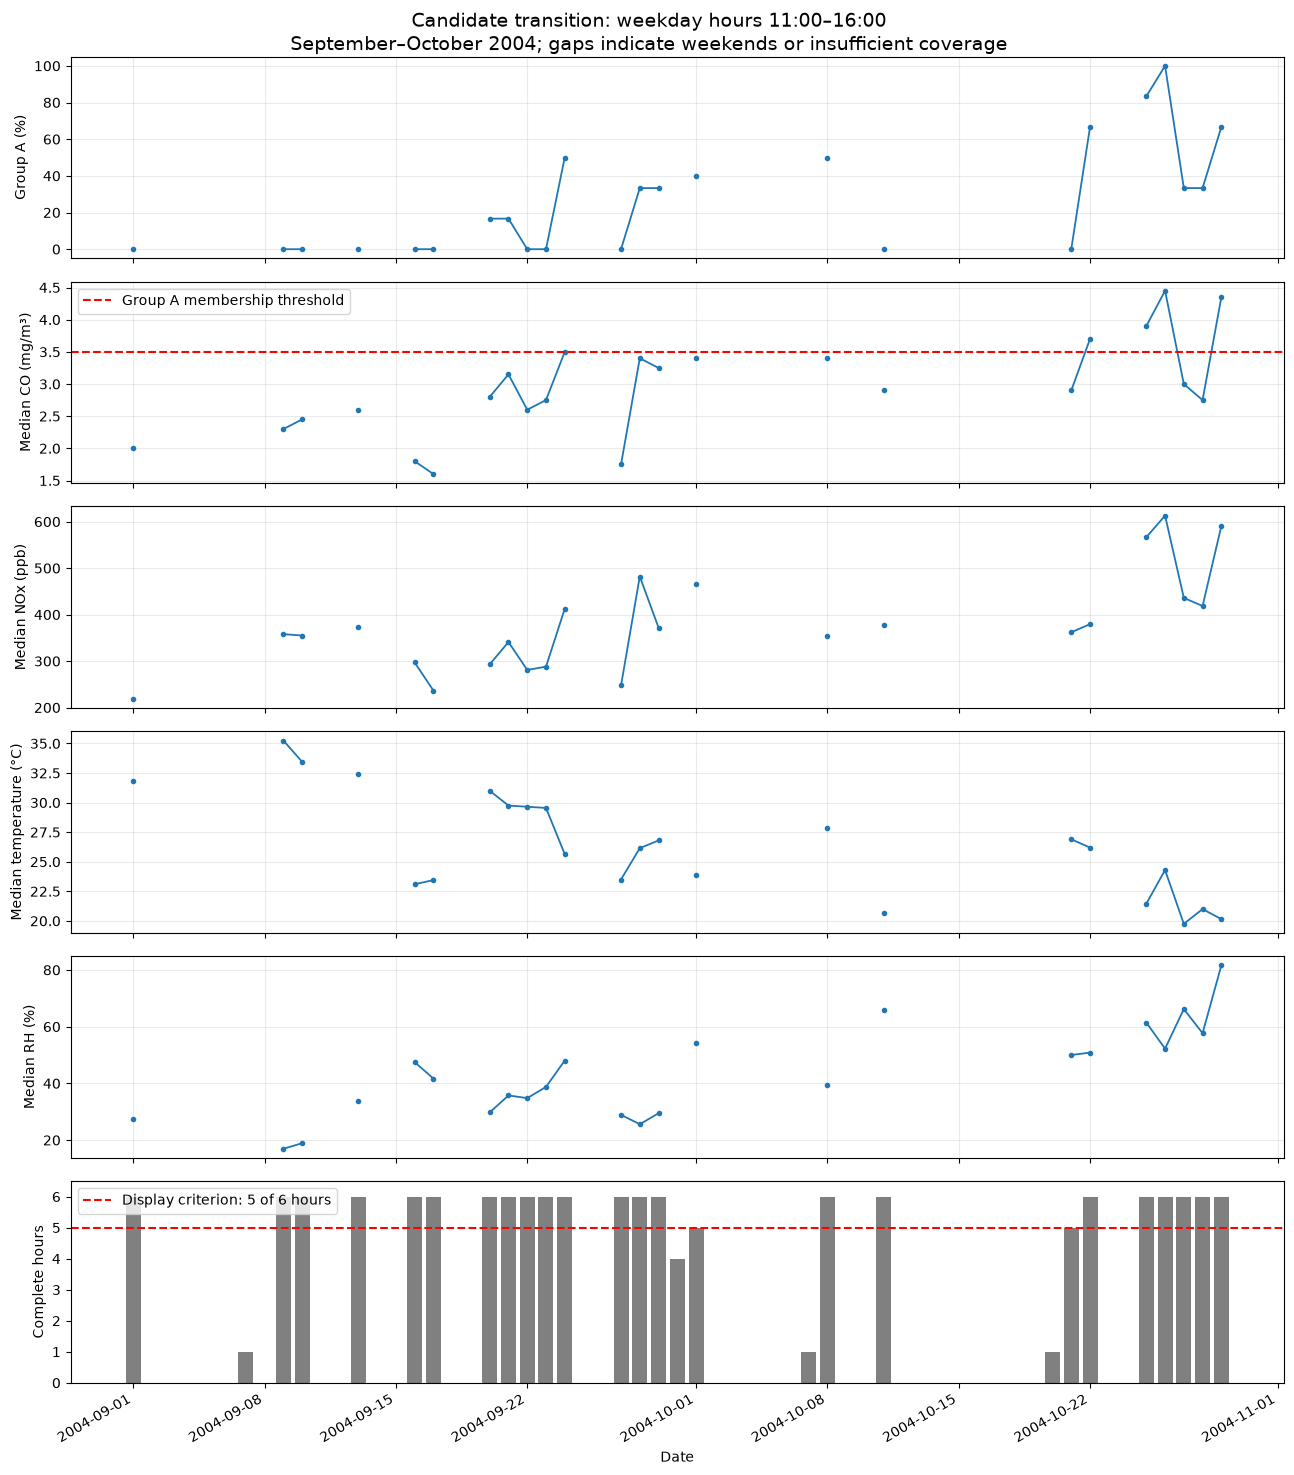

,valid_hours,group_a_hours,group_a_pct,co_median,nox_median,temperature_median,humidity_median
date,,,,,,,
2004-09-01,6,0.0,0.00,2.00,218.5,31.85,27.45
2004-09-02,0,NaN,NaN,NaN,NaN,NaN,NaN
2004-09-03,0,NaN,NaN,NaN,NaN,NaN,NaN
2004-09-06,0,NaN,NaN,NaN,NaN,NaN,NaN
2004-09-07,1,0.0,0.00,1.70,214.0,31.60,25.50
2004-09-08,0,NaN,NaN,NaN,NaN,NaN,NaN
2004-09-09,6,0.0,0.00,2.30,358.0,35.25,16.95
2004-09-10,6,0.0,0.00,2.45,355.0,33.45,18.90
2004-09-13,6,0.0,0.00,2.60,374.0,32.40,33.85


In [3]:
# Investigate weekday daytime patterns during September–October.
# Run after the original group definitions.

start = pd.Timestamp("2004-09-01")
end = pd.Timestamp("2004-10-31")

focus = df.loc[
    df["timestamp"].between(
        start, end + pd.Timedelta(days=1), inclusive="left"
    )
    & (df["timestamp"].dt.dayofweek < 5)
    & df["timestamp"].dt.hour.between(11, 16)
].copy()

focus["day"] = focus["timestamp"].dt.normalize()

daily_focus = focus.groupby("day").agg(
    valid_hours=("group_a", "size"),
    group_a_hours=("group_a", "sum"),
    co_median=("co_gt", "median"),
    nox_median=("nox_gt", "median"),
    temperature_median=("t", "median"),
    humidity_median=("rh", "median")
)

# Include missing days so that lines do not bridge data gaps.
calendar = pd.date_range(start, end, freq="D")
daily_focus = daily_focus.reindex(calendar)
daily_focus.index.name = "date"

daily_focus["valid_hours"] = (
    daily_focus["valid_hours"].fillna(0).astype(int)
)

daily_focus["group_a_pct"] = (
    100 * daily_focus["group_a_hours"]
    / daily_focus["valid_hours"].replace(0, np.nan)
)

# Exploratory coverage rule: at least 5 of the 6 selected hours.
# This is a transparency check, not a guarantee against bias.
min_hours = 5
sufficient = daily_focus["valid_hours"] >= min_hours

plot_columns = [
    "group_a_pct",
    "co_median",
    "nox_median",
    "temperature_median",
    "humidity_median"
]

visible = daily_focus[plot_columns].where(sufficient, axis=0)

fig, axes = plt.subplots(
    6, 1, figsize=(13, 15), sharex=True
)

labels = [
    "Group A (%)",
    "Median CO (mg/m³)",
    "Median NOx (ppb)",
    "Median temperature (°C)",
    "Median RH (%)"
]

for ax, column, label in zip(axes[:5], plot_columns, labels):
    ax.plot(
        visible.index, visible[column],
        marker="o", markersize=3, linewidth=1.3
    )
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)

axes[0].set_ylim(-5, 105)
axes[1].axhline(
    3.5, color="red", linestyle="--",
    label="Group A membership threshold"
)
axes[1].legend()

# Only weekdays are part of the selected cohort.
weekday_mask = daily_focus.index.dayofweek < 5

axes[5].bar(
    daily_focus.index[weekday_mask],
    daily_focus.loc[weekday_mask, "valid_hours"],
    color="grey"
)
axes[5].axhline(
    min_hours, color="red", linestyle="--",
    label="Display criterion: 5 of 6 hours"
)
axes[5].set_ylabel("Complete hours")
axes[5].set_ylim(0, 6.5)
axes[5].legend()
axes[5].set_xlabel("Date")

fig.suptitle(
    "Candidate transition: weekday hours 11:00–16:00\n"
    "September–October 2004; gaps indicate weekends or insufficient coverage",
    fontsize=14
)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

display(
    daily_focus.loc[weekday_mask, [
        "valid_hours", "group_a_hours", "group_a_pct",
        "co_median", "nox_median",
        "temperature_median", "humidity_median"
    ]].round(2)
)

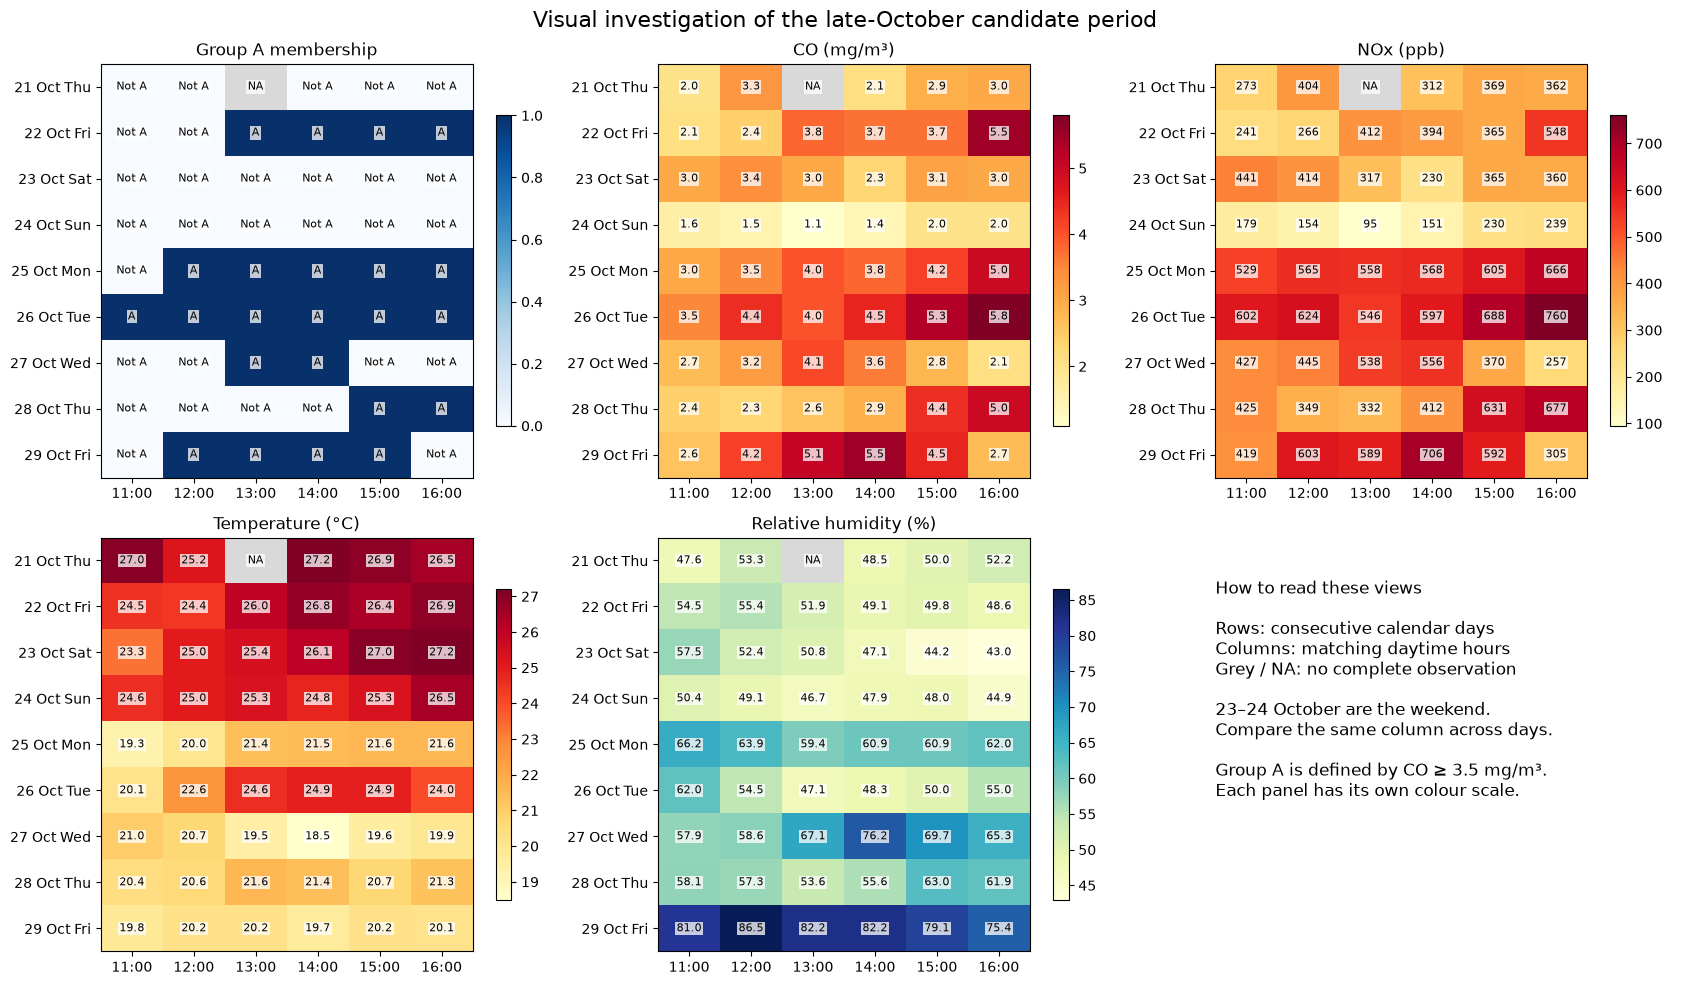

In [4]:
# Zoom into the visually identified late-October candidate period.
# Include weekends to examine recurring weekly patterns.

zoom_start = pd.Timestamp("2004-10-21")
zoom_end = pd.Timestamp("2004-10-29")

zoom = df.loc[
    df["timestamp"].between(
        zoom_start,
        zoom_end + pd.Timedelta(days=1),
        inclusive="left"
    )
    & df["timestamp"].dt.hour.between(11, 16)
].copy()

zoom["day"] = zoom["timestamp"].dt.normalize()
zoom["hour_of_day"] = zoom["timestamp"].dt.hour
zoom["group_a_numeric"] = zoom["group_a"].astype(float)

dates = pd.date_range(zoom_start, zoom_end, freq="D")
hours = list(range(11, 17))

# One observation should correspond to each date-hour combination.
assert not zoom.duplicated(["day", "hour_of_day"]).any()

panels = [
    ("group_a_numeric", "Group A membership", "Blues"),
    ("co_gt", "CO (mg/m³)", "YlOrRd"),
    ("nox_gt", "NOx (ppb)", "YlOrRd"),
    ("t", "Temperature (°C)", "YlOrRd"),
    ("rh", "Relative humidity (%)", "YlGnBu")
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()

for ax, (column, title, colour) in zip(axes, panels):

    matrix = (
        zoom.pivot(
            index="day",
            columns="hour_of_day",
            values=column
        )
        .reindex(index=dates, columns=hours)
    )

    values = matrix.to_numpy(dtype=float)

    cmap = plt.get_cmap(colour).copy()
    cmap.set_bad("#d9d9d9")

    limits = (
        {"vmin": 0, "vmax": 1}
        if column == "group_a_numeric"
        else {}
    )

    image = ax.imshow(
        np.ma.masked_invalid(values),
        aspect="auto",
        cmap=cmap,
        **limits
    )

    ax.set_title(title)
    ax.set_xticks(range(len(hours)))
    ax.set_xticklabels([f"{h}:00" for h in hours])

    ax.set_yticks(range(len(dates)))
    ax.set_yticklabels([
        day.strftime("%d Oct %a") for day in dates
    ])

    for row in range(len(dates)):
        for col in range(len(hours)):
            value = values[row, col]

            if np.isnan(value):
                label = "NA"
            elif column == "group_a_numeric":
                label = "A" if value == 1 else "Not A"
            elif column == "nox_gt":
                label = f"{value:.0f}"
            else:
                label = f"{value:.1f}"

            ax.text(
                col, row, label,
                ha="center", va="center",
                fontsize=8,
                bbox=dict(
                    facecolor="white",
                    alpha=0.75,
                    edgecolor="none",
                    pad=1
                )
            )

    fig.colorbar(image, ax=ax, shrink=0.75)

axes[5].axis("off")
axes[5].text(
    0, 0.9,
    "How to read these views\n\n"
    "Rows: consecutive calendar days\n"
    "Columns: matching daytime hours\n"
    "Grey / NA: no complete observation\n\n"
    "23–24 October are the weekend.\n"
    "Compare the same column across days.\n\n"
    "Group A is defined by CO ≥ 3.5 mg/m³.\n"
    "Each panel has its own colour scale.",
    va="top", fontsize=12
)

fig.suptitle(
    "Visual investigation of the late-October candidate period",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [5]:
# Validate the visually selected candidate episode.
# Compare matching weekdays and hours, using earlier observations only.

audit = df.copy()
audit["weekday"] = audit["timestamp"].dt.dayofweek
audit["hour_of_day"] = audit["timestamp"].dt.hour

# Candidate episode: Monday–Tuesday, 25–26 October, 11:00–16:00.
episode = audit.loc[
    (audit["timestamp"] >= "2004-10-25")
    & (audit["timestamp"] < "2004-10-27")
    & audit["hour_of_day"].between(11, 16)
].copy()

# Earlier Mondays and Tuesdays at the same hours.
reference = audit.loc[
    (audit["timestamp"] >= "2004-09-01")
    & (audit["timestamp"] < "2004-10-25")
    & audit["weekday"].isin([0, 1])
    & audit["hour_of_day"].between(11, 16)
].copy()

reference_summary = (
    reference.groupby(["weekday", "hour_of_day"])
    .agg(
        reference_n=("group_a", "size"),
        reference_a_rate=("group_a", "mean"),
        reference_co=("co_gt", "median"),
        reference_nox=("nox_gt", "median"),
        reference_t=("t", "median"),
        reference_rh=("rh", "median")
    )
    .reset_index()
)

episode_comparison = episode.merge(
    reference_summary,
    on=["weekday", "hour_of_day"],
    how="left",
    validate="many_to_one"
)

episode_comparison["reference_a_pct"] = (
    100 * episode_comparison["reference_a_rate"]
)

for actual, baseline, output in [
    ("co_gt", "reference_co", "co_difference"),
    ("nox_gt", "reference_nox", "nox_difference"),
    ("t", "reference_t", "temperature_difference"),
    ("rh", "reference_rh", "humidity_difference")
]:
    episode_comparison[output] = (
        episode_comparison[actual]
        - episode_comparison[baseline]
    )

display_columns = [
    "timestamp",
    "group_a",
    "reference_n",
    "reference_a_pct",
    "co_gt", "reference_co",
    "nox_gt", "reference_nox",
    "t", "reference_t",
    "rh", "reference_rh"
]

display_table = episode_comparison[display_columns].copy()

# Round numeric columns only; leave timestamps and booleans unchanged.
numeric_columns = display_table.select_dtypes(
    include="number"
).columns

display_table[numeric_columns] = (
    display_table[numeric_columns].round(2)
)

display(display_table)

observed_rate = episode_comparison["group_a"].mean()

# Give each episode weekday-hour slot equal weight.
# Do not pool reference rows with unequal coverage.
matched_reference_rate = (
    episode_comparison["reference_a_rate"].mean()
)

print(
    f"Episode Group A: "
    f"{episode_comparison['group_a'].sum()}/"
    f"{len(episode_comparison)} hours "
    f"({100 * observed_rate:.2f}%)"
)

print(
    "Matched reference Group A rate: "
    f"{100 * matched_reference_rate:.2f}%"
)

print(
    "Descriptive difference: "
    f"{100 * (observed_rate - matched_reference_rate):.2f} "
    "percentage points"
)

print(
    "Reference observations per weekday-hour slot: "
    f"{episode_comparison['reference_n'].min()}–"
    f"{episode_comparison['reference_n'].max()}"
)

print(
    "\nInterpretation: this is a descriptive comparison. "
    "Sparse reference samples and seasonal differences "
    "limit the strength of the conclusion."
)

,timestamp,group_a,reference_n,reference_a_pct,co_gt,reference_co,nox_gt,reference_nox,t,reference_t,rh,reference_rh
0,2004-10-25 11:00:00,False,4,25.0,3.0,2.60,529.0,405.5,19.3,26.80,66.2,37.80
1,2004-10-25 12:00:00,True,4,0.0,3.5,2.85,565.0,341.5,20.0,26.70,63.9,32.80
2,2004-10-25 13:00:00,True,4,0.0,4.0,3.00,558.0,335.5,21.4,26.25,59.4,32.20
3,2004-10-25 14:00:00,True,4,0.0,3.8,2.40,568.0,278.5,21.5,27.15,60.9,31.40
4,2004-10-25 15:00:00,True,4,0.0,4.2,2.20,605.0,308.0,21.6,27.55,60.9,30.05
5,2004-10-25 16:00:00,True,4,0.0,5.0,2.45,666.0,277.5,21.6,29.25,62.0,26.20
6,2004-10-26 11:00:00,True,3,0.0,3.5,3.10,602.0,340.0,20.1,28.50,62.0,29.80
7,2004-10-26 12:00:00,True,2,50.0,4.4,3.55,624.0,428.5,22.6,28.25,54.5,30.75
8,2004-10-26 13:00:00,True,2,100.0,4.0,3.95,546.0,462.5,24.6,27.30,47.1,31.60
9,2004-10-26 14:00:00,True,2,0.0,4.5,2.85,597.0,378.0,24.9,27.65,48.3,31.35


Episode Group A: 11/12 hours (91.67%)
Matched reference Group A rate: 14.58%
Descriptive difference: 77.08 percentage points
Reference observations per weekday-hour slot: 2–4

Interpretation: this is a descriptive comparison. Sparse reference samples and seasonal differences limit the strength of the conclusion.


## 4. Interactive re-examination of the original candidate

The original candidate, 20 September 2004 at 17:00, is
re-examined using interactive hourly views and a comparison
of the multivariate profiles immediately before and after it.

The views distinguish changes in group membership from
changes in pollutant, sensor and environmental attributes.
Groups may overlap.

In [6]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ---------- Prepare a separate plotting copy ----------
event_data = df.copy()
event_data["timestamp"] = pd.to_datetime(
    event_data["timestamp"]
)

# Keep the original Task 1 group definitions.
event_data["group_a"] = event_data["co_gt"] >= 3.5
event_data["group_b"] = (
    (event_data["co_gt"] <= 0.9)
    & (event_data["nox_gt"] <= 90)
)
event_data["group_c"] = (
    (event_data["t"] >= 26)
    & (event_data["rh"] <= 35)
)
event_data["group_d"] = event_data["t"] <= 10

def membership_label(row):
    groups = [
        name
        for name, column in [
            ("A", "group_a"),
            ("B", "group_b"),
            ("C", "group_c"),
            ("D", "group_d")
        ]
        if row[column]
    ]
    return ", ".join(groups) if groups else "None"

event_data["memberships"] = event_data.apply(
    membership_label, axis=1
)

before_time = pd.Timestamp("2004-09-20 16:00")
after_time = pd.Timestamp("2004-09-20 17:00")

indexed = event_data.set_index("timestamp").sort_index()

assert indexed.index.is_unique, "Duplicate timestamps found."
assert before_time in indexed.index
assert after_time in indexed.index

# Reindex to all 24 hours: missing observations remain gaps.
day_index = pd.date_range(
    "2004-09-20 00:00",
    "2004-09-20 23:00",
    freq="h"
)
event_day = indexed.reindex(day_index)

profiles = indexed.loc[[before_time, after_time]].copy()

# ---------- Figure 1: interactive hourly context ----------
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    subplot_titles=[
        "Hourly CO and the Group A threshold",
        "Hourly NOx"
    ],
    vertical_spacing=0.12
)

for row_number, column, unit in [
    (1, "co_gt", "mg/m³"),
    (2, "nox_gt", "ppb")
]:
    fig.add_trace(
        go.Scatter(
            x=event_day.index,
            y=event_day[column],
            mode="lines+markers",
            connectgaps=False,
            name=column,
            customdata=event_day["memberships"]
                .fillna("Missing complete observation")
                .to_numpy(),
            hovertemplate=(
                "%{x|%d %b %H:%M}"
                f"<br>Value: %{{y:.2f}} {unit}"
                "<br>Groups: %{customdata}"
                "<extra></extra>"
            )
        ),
        row=row_number,
        col=1
    )

    for timestamp, colour, label in [
        (before_time, "#0072B2", "Before: 16:00"),
        (after_time, "#D55E00", "Candidate: 17:00")
    ]:
        fig.add_trace(
            go.Scatter(
                x=[timestamp],
                y=[indexed.loc[timestamp, column]],
                mode="markers",
                marker=dict(
                    size=13,
                    color=colour,
                    symbol="diamond"
                ),
                name=label,
                legendgroup=label,
                showlegend=(row_number == 1),
                hovertemplate=(
                    f"{label}"
                    f"<br>%{{y:.2f}} {unit}"
                    "<extra></extra>"
                )
            ),
            row=row_number,
            col=1
        )

fig.add_hline(
    y=3.5,
    line_dash="dash",
    line_color="red",
    annotation_text="Group A: CO ≥ 3.5 mg/m³",
    row=1,
    col=1
)

fig.update_yaxes(title_text="CO (mg/m³)", row=1, col=1)
fig.update_yaxes(title_text="NOx (ppb)", row=2, col=1)
fig.update_xaxes(title_text="Time on 20 September 2004", row=2, col=1)

fig.update_layout(
    title="Original candidate: hourly context",
    template="plotly_white",
    height=650,
    hovermode="x unified"
)

fig.show()

# ---------- Figure 2: interactive multivariate profiles ----------
attributes = [
    "co_gt", "c6h6_gt", "nox_gt", "no2_gt",
    "s1_co", "s5_o3", "t", "rh"
]

labels = [
    "CO", "C6H6", "NOx", "NO2",
    "S1", "S5", "Temperature", "RH"
]

units = [
    "mg/m³", "µg/m³", "ppb", "µg/m³",
    "sensor response", "sensor response", "°C", "%"
]

# Fixed reference scale across the complete dataset.
# Values outside this range are retained, not clipped.
lower = event_data[attributes].quantile(0.01)
upper = event_data[attributes].quantile(0.99)
span = (upper - lower).replace(0, np.nan)

profile_fig = go.Figure()

for timestamp, colour, dash in [
    (before_time, "#0072B2", "dash"),
    (after_time, "#D55E00", "solid")
]:
    record = profiles.loc[timestamp]
    raw_values = record[attributes].astype(float)
    scaled_values = (raw_values - lower) / span

    hover_details = [
        f"{label}: {value:.2f} {unit}"
        for label, value, unit
        in zip(labels, raw_values, units)
    ]

    profile_fig.add_trace(
        go.Scatter(
            x=labels,
            y=scaled_values,
            mode="lines+markers",
            name=(
                f"{timestamp:%H:%M} — "
                f"Groups: {record['memberships']}"
            ),
            line=dict(color=colour, dash=dash, width=3),
            marker=dict(size=8),
            text=hover_details,
            hovertemplate="%{text}<extra>%{fullData.name}</extra>"
        )
    )

profile_fig.update_layout(
    title=(
        "Before and after: multivariate profiles"
        "<br><sup>Fixed 1st–99th percentile scaling; "
        "hover for original values and units</sup>"
    ),
    xaxis_title="Task 1 attributes",
    yaxis_title="Position relative to fixed reference range",
    template="plotly_white",
    height=500,
    hovermode="closest"
)

profile_fig.show()

# Exact membership audit.
display(
    profiles[
        attributes
        + ["group_a", "group_b", "group_c", "group_d", "memberships"]
    ]
)

,co_gt,c6h6_gt,nox_gt,no2_gt,s1_co,s5_o3,t,rh,group_a,group_b,group_c,group_d,memberships
timestamp,,,,,,,,,,,,,
2004-09-20 16:00:00,2.6,15.5,280.0,124.0,1169.0,1025.0,34.3,23.2,False,False,True,False,C
2004-09-20 17:00:00,5.0,28.8,505.0,184.0,1386.0,1469.0,34.1,23.0,True,False,True,False,"A, C"


## 5. Temporal Transition Analysis

This section investigates temporal changes in the visually identified
groups, focusing on August–September 2004 as suggested by Task 2.

Daily group membership proportions are calculated using the number
of valid observations per day as the denominator.

The initial analysis aims to identify candidate transition periods.
A specific critical moment will subsequently be examined using
higher-resolution temporal and multivariate evidence.

In [7]:
# Focus on August–September 2004
transition_df = df[
    (df["timestamp"] >= "2004-08-01") &
    (df["timestamp"] < "2004-10-01")
].copy()

# Aggregate daily group membership
daily = (
    transition_df
    .groupby(transition_df["timestamp"].dt.floor("D"))
    .agg(
        valid_hours=("group_a", "size"),
        group_a_hours=("group_a", "sum"),
        group_b_hours=("group_b", "sum"),
        group_c_hours=("group_c", "sum"),
        group_d_hours=("group_d", "sum")
    )
)

# Calculate proportions based on valid observations
for group in ["a", "b", "c", "d"]:
    daily[f"group_{group}_pct"] = (
        daily[f"group_{group}_hours"] /
        daily["valid_hours"] * 100
    )

display(daily.head())

print("Number of days:", len(daily))
print("Total valid hours:", daily["valid_hours"].sum())

,valid_hours,group_a_hours,group_b_hours,group_c_hours,group_d_hours,group_a_pct,group_b_pct,group_c_pct,group_d_pct
timestamp,,,,,,,,,
2004-08-01,23,0,15,9,0,0.0,65.217391,39.130435,0.0
2004-08-02,22,0,6,9,0,0.0,27.272727,40.909091,0.0
2004-08-03,1,0,1,0,0,0.0,100.000000,0.000000,0.0
2004-08-06,19,0,1,3,0,0.0,5.263158,15.789474,0.0
2004-08-07,23,0,5,8,0,0.0,21.739130,34.782609,0.0


Number of days: 48
Total valid hours: 848


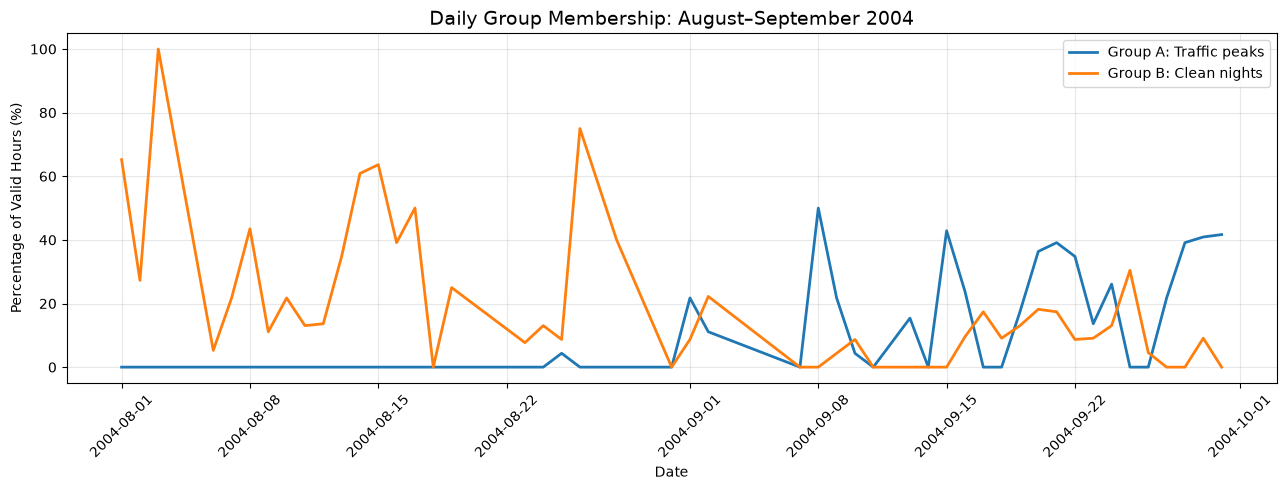

In [8]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    daily.index,
    daily["group_a_pct"],
    label="Group A: Traffic peaks",
    linewidth=2
)

ax.plot(
    daily.index,
    daily["group_b_pct"],
    label="Group B: Clean nights",
    linewidth=2
)

ax.set_title(
    "Daily Group Membership: August–September 2004",
    fontsize=14
)

ax.set_xlabel("Date")
ax.set_ylabel("Percentage of Valid Hours (%)")

ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Data Completeness Assessment

Before identifying a critical moment, data completeness is assessed
to reduce the risk of interpreting missing observations as genuine
temporal changes.

The number of valid hourly observations is examined for each day
during August–September 2004.

Days with fewer than 18 valid observations are flagged as
low-coverage days. This threshold is used as an exploratory
reliability criterion rather than a guarantee of unbiased estimates.

The analysis also considers whether missing observations may
systematically affect the interpretation of group membership.

In [9]:
# Create a complete daily date range
full_dates = pd.date_range(
    start="2004-08-01",
    end="2004-09-30",
    freq="D"
)

# Include dates with no complete observations
daily_complete = daily.reindex(full_dates).copy()

# Fill missing counts with zero
count_columns = [
    "valid_hours",
    "group_a_hours",
    "group_b_hours",
    "group_c_hours",
    "group_d_hours"
]

daily_complete[count_columns] = (
    daily_complete[count_columns].fillna(0)
)

# Recalculate daily percentages
for group in ["a", "b", "c", "d"]:
    daily_complete[f"group_{group}_pct"] = (
        daily_complete[f"group_{group}_hours"]
        .div(daily_complete["valid_hours"].replace(0, np.nan))
        * 100
    )

# Flag low-coverage days
daily_complete["sufficient_coverage"] = (
    daily_complete["valid_hours"] >= 18
)

print("Total calendar days:", len(daily_complete))

print(
    "Days with sufficient coverage:",
    daily_complete["sufficient_coverage"].sum()
)

print(
    "Days with insufficient coverage:",
    (~daily_complete["sufficient_coverage"]).sum()
)

display(
    daily_complete[
        daily_complete["valid_hours"] < 18
    ][["valid_hours", "group_a_pct", "group_b_pct"]]
)

Total calendar days: 61
Days with sufficient coverage: 33
Days with insufficient coverage: 28


,valid_hours,group_a_pct,group_b_pct
2004-08-03,1.0,0.000000,100.000000
2004-08-04,0.0,NaN,NaN
2004-08-05,0.0,NaN,NaN
2004-08-17,10.0,0.000000,50.000000
2004-08-18,8.0,0.000000,0.000000
2004-08-20,0.0,NaN,NaN
2004-08-21,0.0,NaN,NaN
2004-08-22,0.0,NaN,NaN
2004-08-23,13.0,0.000000,7.692308
2004-08-26,4.0,0.000000,75.000000


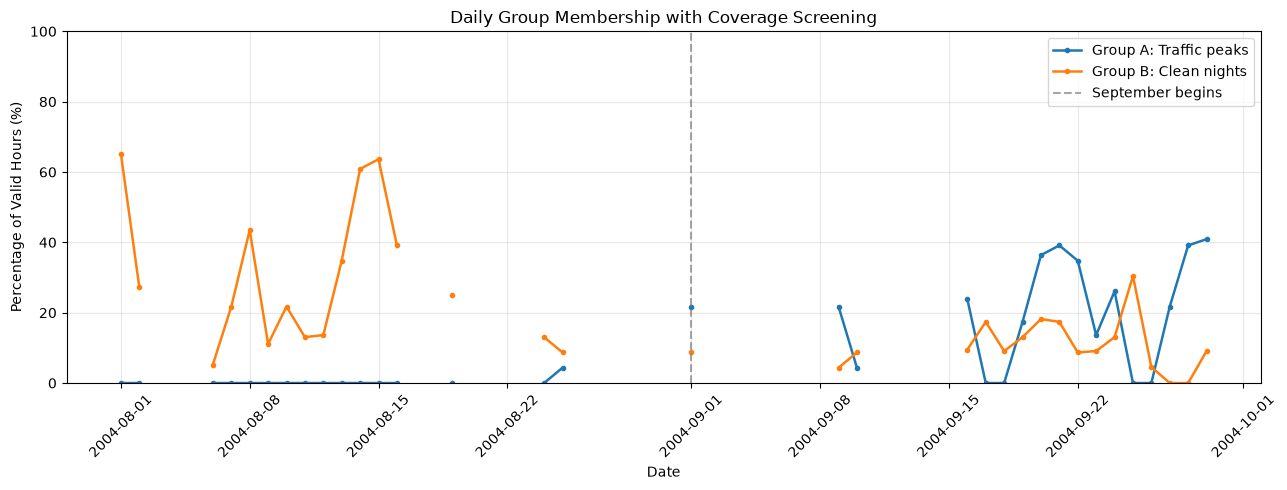

In [10]:
# Retain percentages only for sufficiently covered days
plot_daily = daily_complete.copy()

for group in ["a", "b"]:
    plot_daily.loc[
        ~plot_daily["sufficient_coverage"],
        f"group_{group}_pct"
    ] = np.nan

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    plot_daily.index,
    plot_daily["group_a_pct"],
    label="Group A: Traffic peaks",
    marker="o",
    markersize=3,
    linewidth=1.8
)

ax.plot(
    plot_daily.index,
    plot_daily["group_b_pct"],
    label="Group B: Clean nights",
    marker="o",
    markersize=3,
    linewidth=1.8
)

ax.axvline(
    pd.Timestamp("2004-09-01"),
    linestyle="--",
    color="grey",
    alpha=0.7,
    label="September begins"
)

ax.set_title(
    "Daily Group Membership with Coverage Screening"
)

ax.set_xlabel("Date")
ax.set_ylabel("Percentage of Valid Hours (%)")

ax.set_ylim(0, 100)

ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Identifying Candidate Critical Moments

To identify potential critical moments, the analysis compares
group membership proportions before and after each candidate date.

A seven-day window is used on each side of the candidate date.
Only days with at least 18 valid hourly observations are included.

To reduce the influence of missing data, each window must contain
at least four sufficiently covered days.

Group proportions are calculated using the total number of
observations belonging to each group divided by the total number
of valid observations in the corresponding window.

The magnitude of change in Groups A and B is used to identify
candidate transition dates.

These dates are treated as exploratory candidates rather than
confirmed critical moments. Further investigation of pollutant
measurements and environmental conditions is required.

In [11]:
# Identify candidate critical moments using 7-day windows

window = 7
min_covered_days = 4

results = []

for candidate_date in daily_complete.index[window:-window]:

    before = daily_complete.loc[
        candidate_date - pd.Timedelta(days=window):
        candidate_date - pd.Timedelta(days=1)
    ]

    after = daily_complete.loc[
        candidate_date:
        candidate_date + pd.Timedelta(days=window-1)
    ]

    # Retain sufficiently covered days
    before = before[before["sufficient_coverage"]]
    after = after[after["sufficient_coverage"]]

    # Require enough reliable days on both sides
    if (
        len(before) < min_covered_days
        or len(after) < min_covered_days
    ):
        continue

    before_valid = before["valid_hours"].sum()
    after_valid = after["valid_hours"].sum()

    # Calculate observation-weighted proportions
    before_a = (
        before["group_a_hours"].sum()
        / before_valid * 100
    )

    after_a = (
        after["group_a_hours"].sum()
        / after_valid * 100
    )

    before_b = (
        before["group_b_hours"].sum()
        / before_valid * 100
    )

    after_b = (
        after["group_b_hours"].sum()
        / after_valid * 100
    )

    change_a = after_a - before_a
    change_b = after_b - before_b

    results.append({
        "candidate_date": candidate_date,
        "before_covered_days": len(before),
        "after_covered_days": len(after),
        "before_valid_hours": before_valid,
        "after_valid_hours": after_valid,
        "change_group_a_pp": change_a,
        "change_group_b_pp": change_b,
        "combined_change_score": (
            abs(change_a) + abs(change_b)
        )
    })

candidate_df = pd.DataFrame(results)

if candidate_df.empty:
    print("No candidate dates satisfy the coverage requirements.")
else:
    candidate_df = candidate_df.sort_values(
        "combined_change_score",
        ascending=False
    )

    numeric_columns = candidate_df.select_dtypes("number").columns
    display(candidate_df.head(10).round({col: 2 for col in numeric_columns}))

,candidate_date,before_covered_days,after_covered_days,before_valid_hours,after_valid_hours,change_group_a_pp,change_group_b_pp,combined_change_score
5,2004-08-13,7,5,151.0,111.0,0.00,25.84,25.84
6,2004-08-14,7,4,155.0,88.0,0.00,24.50,24.50
4,2004-08-12,6,5,129.0,113.0,0.00,22.32,22.32
3,2004-08-11,5,6,106.0,136.0,0.00,15.80,15.80
7,2004-09-20,4,7,89.0,158.0,11.41,2.20,13.60
2,2004-08-10,4,7,83.0,159.0,0.00,13.53,13.53
1,2004-08-09,4,7,87.0,154.0,0.00,6.53,6.53
8,2004-09-21,5,7,111.0,159.0,4.18,-1.56,5.75
10,2004-09-23,7,7,157.0,158.0,-1.40,-3.88,5.29
9,2004-09-22,6,7,134.0,159.0,0.09,-4.75,4.84


## 8. Investigating the September Transition

The seven-day comparison identified 20 September 2004
as a candidate transition date, with an 11.41 percentage-point
increase in Group A.

Since Group A represents traffic-related pollution peaks,
this period is selected for further investigation.

To assess whether the observed change reflects a meaningful
pollution transition, we examine CO, NOx, temperature,
and relative humidity around the candidate date.

Daily median values are used to reduce the influence of
extreme hourly observations.

The purpose is to investigate whether changes in group
membership coincide with changes in pollutant concentrations
and environmental conditions, without assuming causation.

In [12]:
# Step 7: Investigate the September transition

import matplotlib.pyplot as plt
import pandas as pd

# Ensure timestamp is datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Candidate date identified in Step 6
critical_candidate = pd.Timestamp("2004-09-20")

# Examine 7 days before and after
start_date = critical_candidate - pd.Timedelta(days=7)
end_date = critical_candidate + pd.Timedelta(days=7)

transition_df = df[
    (df["timestamp"] >= start_date) &
    (df["timestamp"] < end_date)
].copy()

# Create daily summaries
daily_transition = (
    transition_df
    .set_index("timestamp")
    .resample("D")
    .agg({
        "co_gt": "median",
        "nox_gt": "median",
        "t": "median",
        "rh": "median",
        "group_a": "mean",
        "group_b": "mean"
    })
)

# Convert group proportions to percentages
daily_transition["group_a"] *= 100
daily_transition["group_b"] *= 100

display(daily_transition.round(2))

,co_gt,nox_gt,t,rh,group_a,group_b
timestamp,,,,,,
2004-09-13,3.00,395.0,30.00,36.60,15.38,0.00
2004-09-14,0.75,127.0,24.75,49.10,0.00,0.00
2004-09-15,3.30,341.0,23.90,58.90,42.86,0.00
2004-09-16,2.00,315.0,21.60,59.10,23.81,9.52
2004-09-17,1.60,239.0,22.10,43.20,0.00,17.39
2004-09-18,1.40,183.5,24.50,38.30,0.00,9.09
2004-09-19,1.80,189.0,24.70,46.40,17.39,13.04
2004-09-20,2.60,281.5,25.60,36.05,36.36,18.18
2004-09-21,3.10,340.0,23.60,47.70,39.13,17.39


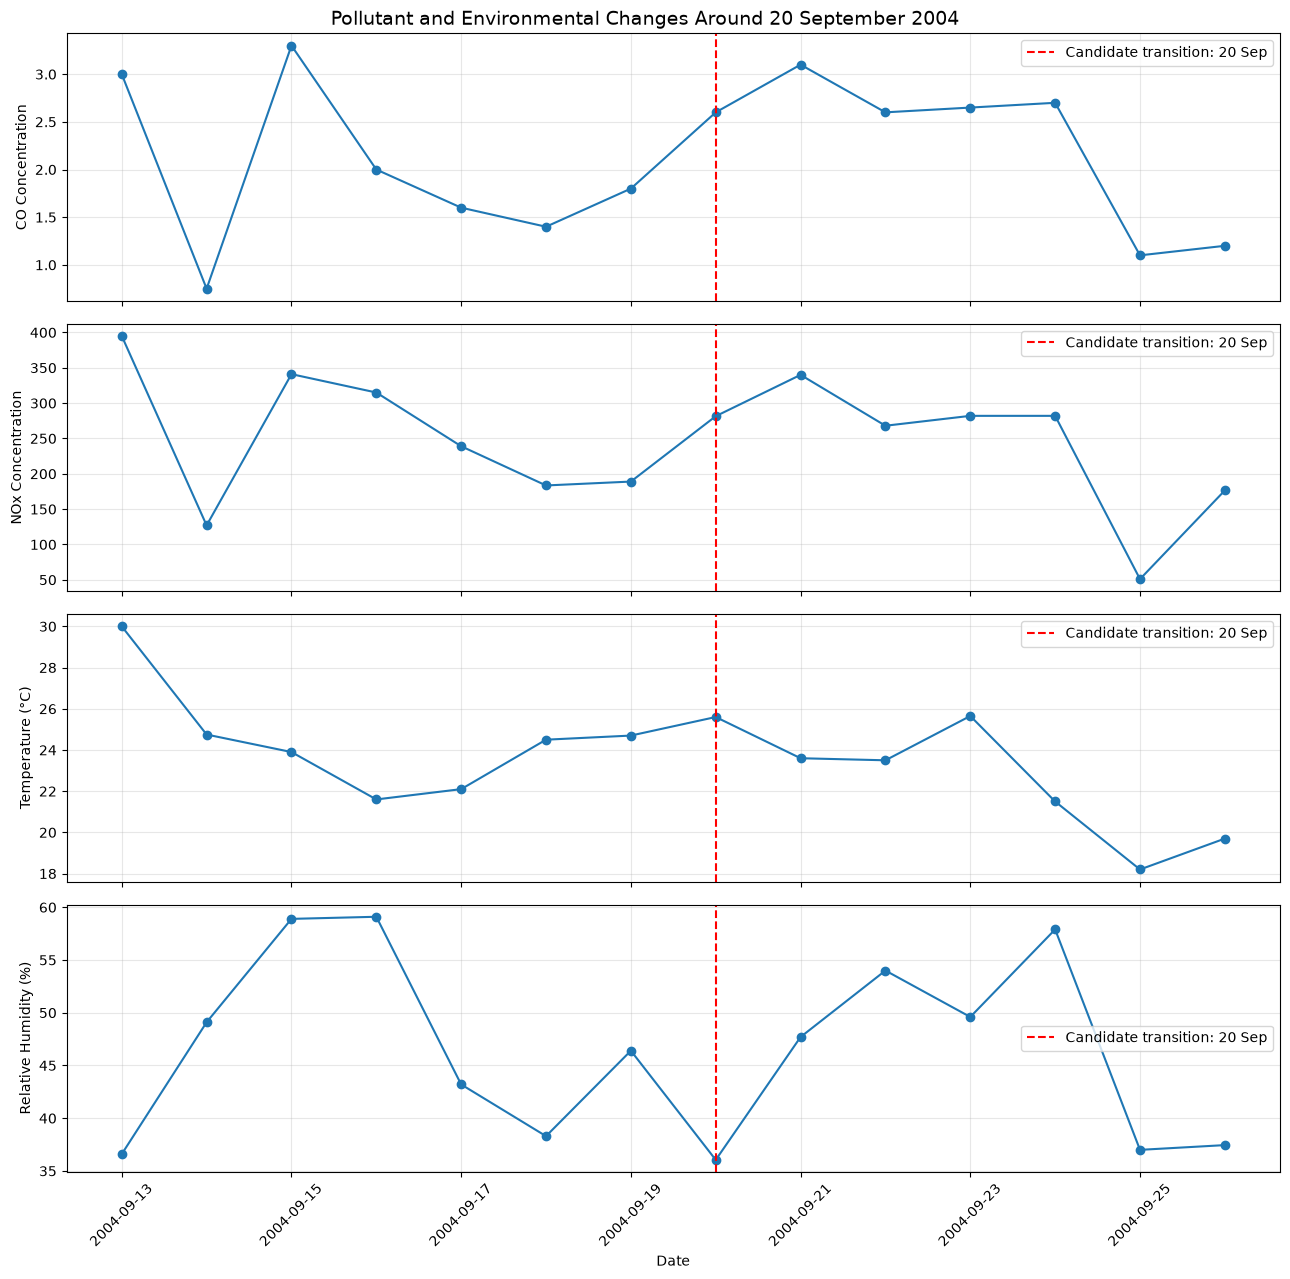

In [13]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(13, 13),
    sharex=True
)

variables = [
    ("co_gt", "CO Concentration"),
    ("nox_gt", "NOx Concentration"),
    ("t", "Temperature (°C)"),
    ("rh", "Relative Humidity (%)")
]

for ax, (column, label) in zip(axes, variables):

    ax.plot(
        daily_transition.index,
        daily_transition[column],
        marker="o"
    )

    ax.axvline(
        critical_candidate,
        color="red",
        linestyle="--",
        label="Candidate transition: 20 Sep"
    )

    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")

fig.suptitle(
    "Pollutant and Environmental Changes Around "
    "20 September 2004",
    fontsize=14
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Validating Data Coverage Around the Candidate Transition

Before confirming 20 September 2004 as a critical moment,
we assess the completeness of the hourly observations.

Daily median values may be misleading when only a small
number of valid hourly measurements are available.

We therefore examine the number of observations for CO,
NOx, temperature and relative humidity on each day.

Days with fewer than 18 available hourly observations
are flagged for further investigation.

This assessment helps distinguish potential environmental
changes from patterns influenced by missing data.

In [14]:
# Step 8: Validate data coverage around the candidate transition

# Count valid observations for each variable
daily_coverage = (
    transition_df
    .set_index("timestamp")
    .resample("D")
    .agg(
        total_hours=("co_gt", "size"),
        co_valid=("co_gt", "count"),
        nox_valid=("nox_gt", "count"),
        temperature_valid=("t", "count"),
        humidity_valid=("rh", "count"),
        group_a_hours=("group_a", "sum")
    )
)

# Calculate the percentage of Group A observations
daily_coverage["group_a_pct"] = (
    daily_coverage["group_a_hours"]
    / daily_coverage["total_hours"]
    * 100
)

# Flag days with insufficient observations
daily_coverage["sufficient_coverage"] = (
    (daily_coverage["total_hours"] >= 18)
    & (daily_coverage["co_valid"] >= 18)
    & (daily_coverage["nox_valid"] >= 18)
    & (daily_coverage["temperature_valid"] >= 18)
    & (daily_coverage["humidity_valid"] >= 18)
)

display(daily_coverage.round(2))

print(
    "Days with sufficient coverage:",
    daily_coverage["sufficient_coverage"].sum()
)

print(
    "Days with insufficient coverage:",
    (~daily_coverage["sufficient_coverage"]).sum()
)

,total_hours,co_valid,nox_valid,temperature_valid,humidity_valid,group_a_hours,group_a_pct,sufficient_coverage
timestamp,,,,,,,,
2004-09-13,13,13,13,13,13,2,15.38,False
2004-09-14,2,2,2,2,2,0,0.00,False
2004-09-15,7,7,7,7,7,3,42.86,False
2004-09-16,21,21,21,21,21,5,23.81,True
2004-09-17,23,23,23,23,23,0,0.00,True
2004-09-18,22,22,22,22,22,0,0.00,True
2004-09-19,23,23,23,23,23,4,17.39,True
2004-09-20,22,22,22,22,22,8,36.36,True
2004-09-21,23,23,23,23,23,9,39.13,True


Days with sufficient coverage: 11
Days with insufficient coverage: 3


## 10. Hourly Critical Moment Analysis

The daily analysis identified 19–21 September 2004
as a period of interest.

Group A increased from 17.39% on 19 September
to 36.36% on 20 September and 39.13% on
21 September.

The selected dates have sufficient data coverage,
making them suitable for further investigation.

However, daily aggregation may conceal short-term
changes and recurring hourly patterns.

We therefore examine hourly CO and NOx measurements
alongside Group A membership to identify when
the observed transition occurred.

This analysis aims to distinguish an abrupt transition
from normal daily fluctuations.

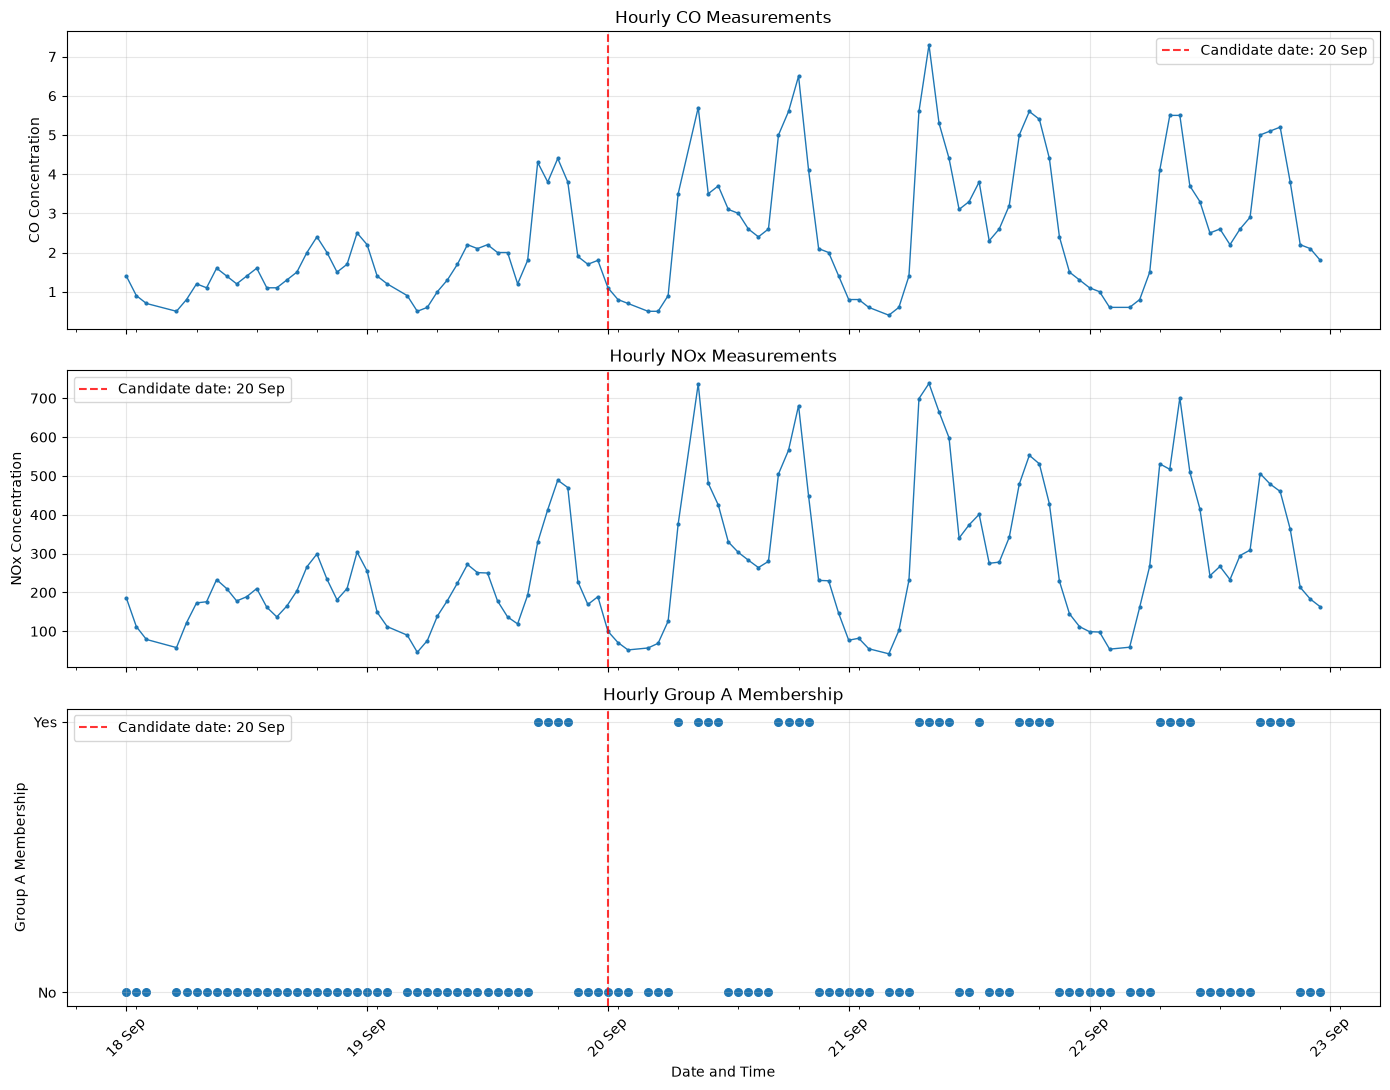

In [15]:
# Step 9: Hourly Critical Moment Analysis

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Select the period of interest
hourly_start = pd.Timestamp("2004-09-18")
hourly_end = pd.Timestamp("2004-09-23")

hourly_df = df[
    (df["timestamp"] >= hourly_start) &
    (df["timestamp"] < hourly_end)
].copy()

hourly_df = hourly_df.sort_values("timestamp")

# Create three vertically aligned plots
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

# Plot 1: CO
axes[0].plot(
    hourly_df["timestamp"],
    hourly_df["co_gt"],
    marker=".",
    markersize=4,
    linewidth=1
)

axes[0].set_ylabel("CO Concentration")
axes[0].set_title("Hourly CO Measurements")
axes[0].grid(alpha=0.3)

# Plot 2: NOx
axes[1].plot(
    hourly_df["timestamp"],
    hourly_df["nox_gt"],
    marker=".",
    markersize=4,
    linewidth=1
)

axes[1].set_ylabel("NOx Concentration")
axes[1].set_title("Hourly NOx Measurements")
axes[1].grid(alpha=0.3)

# Plot 3: Group A membership
axes[2].scatter(
    hourly_df["timestamp"],
    hourly_df["group_a"].astype(int),
    s=30
)

axes[2].set_ylabel("Group A Membership")
axes[2].set_title("Hourly Group A Membership")
axes[2].set_yticks([0, 1])
axes[2].set_yticklabels(["No", "Yes"])
axes[2].grid(alpha=0.3)

# Mark the candidate transition date
candidate_date = pd.Timestamp("2004-09-20")

for ax in axes:
    ax.axvline(
        candidate_date,
        color="red",
        linestyle="--",
        alpha=0.8,
        label="Candidate date: 20 Sep"
    )
    ax.legend()

# Format time axis
axes[2].xaxis.set_major_locator(
    mdates.DayLocator()
)

axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

axes[2].xaxis.set_minor_locator(
    mdates.HourLocator(interval=6)
)

axes[2].set_xlabel("Date and Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11. Weekend vs Weekday Pattern Analysis

The hourly analysis revealed an increase in CO and NOx
concentrations and more frequent Group A observations
around 20 September 2004.

However, 20 September was a Monday, suggesting that
the observed transition may be associated with the
change from weekend to weekday conditions.

To investigate this possibility, we compare hourly
pollution profiles and Group A membership between
weekdays and weekends.

This comparison helps determine whether the
candidate critical moment represents an unusual
transition or a recurring temporal pattern.

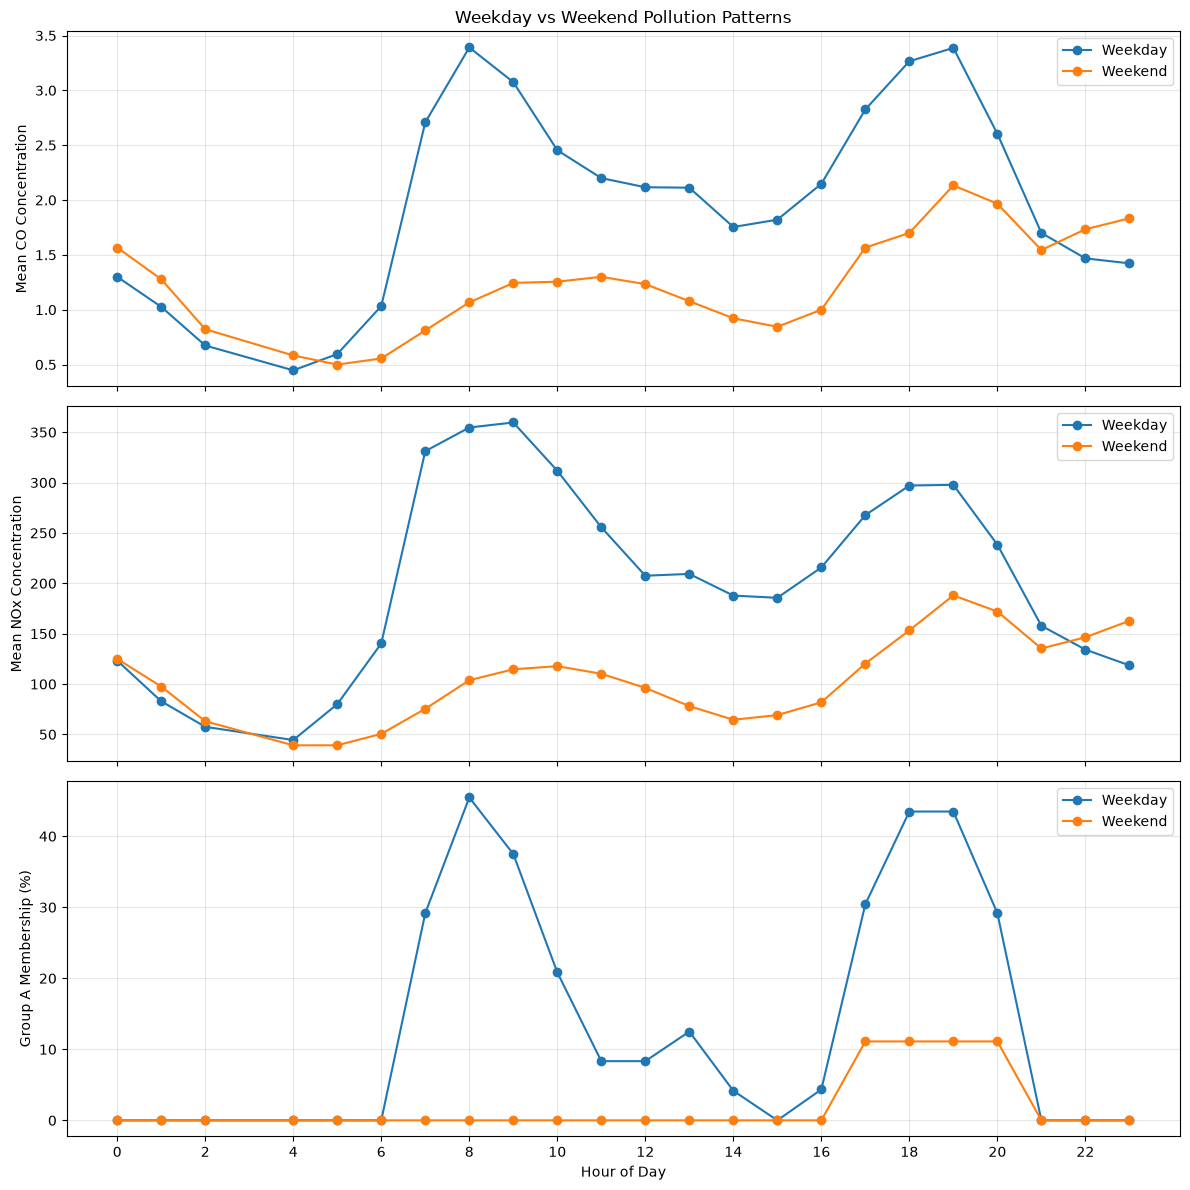

Number of observations:
day_type
Weekday    533
Weekend    204
Name: count, dtype: int64

Number of sufficiently covered days:
day_type
Weekday    24
Weekend     9
Name: calendar_date, dtype: int64


In [16]:
# Step 10: Weekend vs Weekday Pattern Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Prepare data
comparison_df = df.copy()

comparison_df["timestamp"] = pd.to_datetime(
    comparison_df["timestamp"]
)

comparison_df["day_of_week"] = (
    comparison_df["timestamp"].dt.dayofweek
)

comparison_df["day_type"] = comparison_df[
    "day_of_week"
].apply(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

comparison_df["hour_of_day"] = (
    comparison_df["timestamp"].dt.hour
)

# Use August–September 2004 for seasonal comparability
comparison_df = comparison_df[
    (comparison_df["timestamp"] >= "2004-08-01") &
    (comparison_df["timestamp"] < "2004-10-01")
].copy()

# Apply the same daily coverage criterion
comparison_df["calendar_date"] = (
    comparison_df["timestamp"].dt.normalize()
)

daily_counts = comparison_df.groupby(
    "calendar_date"
).size()

sufficient_dates = daily_counts[
    daily_counts >= 18
].index

comparison_df = comparison_df[
    comparison_df["calendar_date"].isin(sufficient_dates)
].copy()

# Summarise hourly patterns
hourly_comparison = (
    comparison_df.groupby(
        ["day_type", "hour_of_day"]
    )
    .agg(
        mean_co=("co_gt", "mean"),
        mean_nox=("nox_gt", "mean"),
        group_a_pct=("group_a", lambda x: x.mean() * 100),
        observations=("group_a", "size")
    )
    .reset_index()
)

# Plot results
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 12),
    sharex=True
)

metrics = [
    ("mean_co", "Mean CO Concentration"),
    ("mean_nox", "Mean NOx Concentration"),
    ("group_a_pct", "Group A Membership (%)")
]

for ax, (metric, ylabel) in zip(axes, metrics):

    for day_type in ["Weekday", "Weekend"]:

        subset = hourly_comparison[
            hourly_comparison["day_type"] == day_type
        ]

        ax.plot(
            subset["hour_of_day"],
            subset[metric],
            marker="o",
            label=day_type
        )

    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_title(
    "Weekday vs Weekend Pollution Patterns"
)

axes[2].set_xlabel("Hour of Day")
axes[2].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

# Check sample sizes
print("Number of observations:")
print(comparison_df["day_type"].value_counts())

print("\nNumber of sufficiently covered days:")
print(
    comparison_df.groupby("day_type")[
        "calendar_date"
    ].nunique()
)

## 12. Critical Moment Validation

The weekday–weekend comparison revealed clear differences
in pollution profiles, particularly during morning and
evening peak hours.

This suggests that the apparent transition around
20 September 2004 may reflect a recurring weekday pattern
rather than an unusual pollution event.

To evaluate this possibility, we compare the hourly
pollution measurements on 20 September with the
corresponding hourly patterns observed on other weekdays.

This comparison helps assess whether the candidate
critical moment exhibits unusual pollution behaviour
beyond the normal weekday cycle.

Candidate observations: 22
Baseline observations: 511
Baseline weekdays: 23


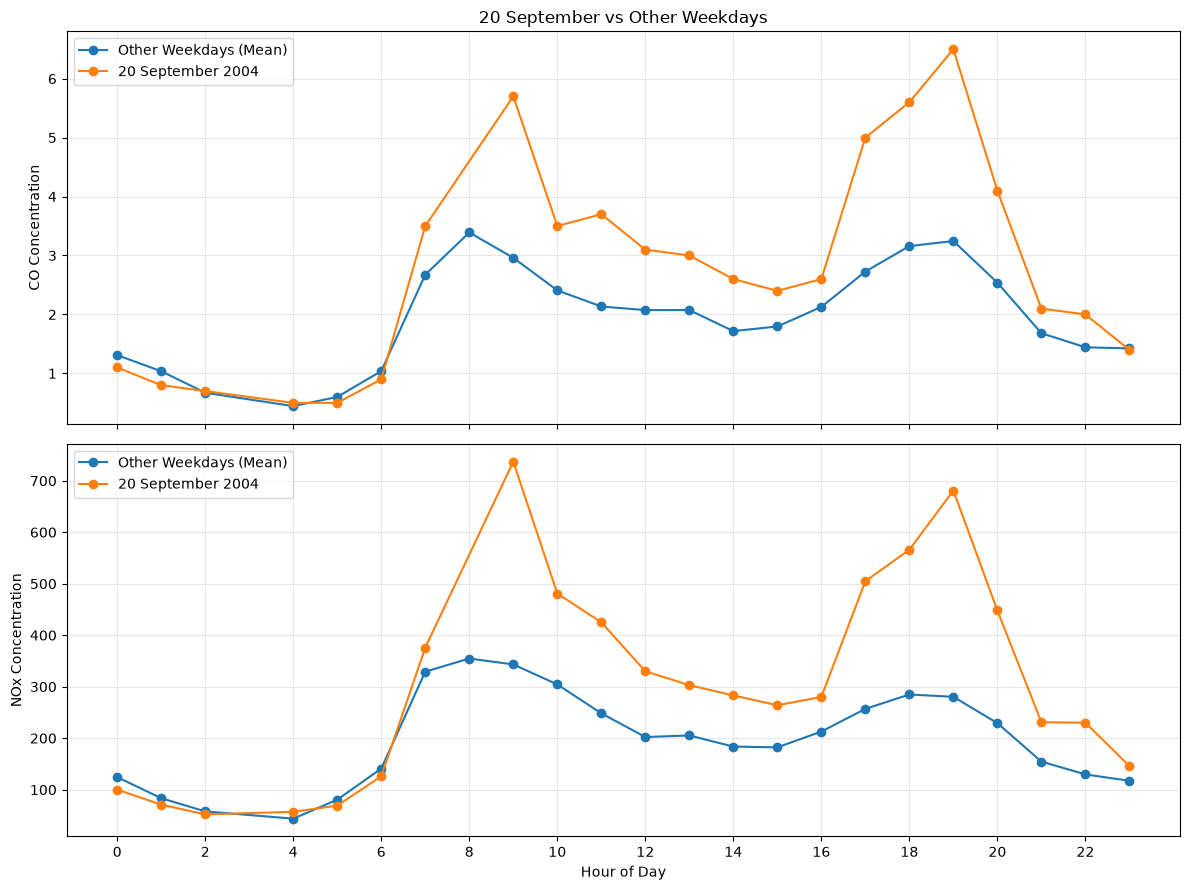

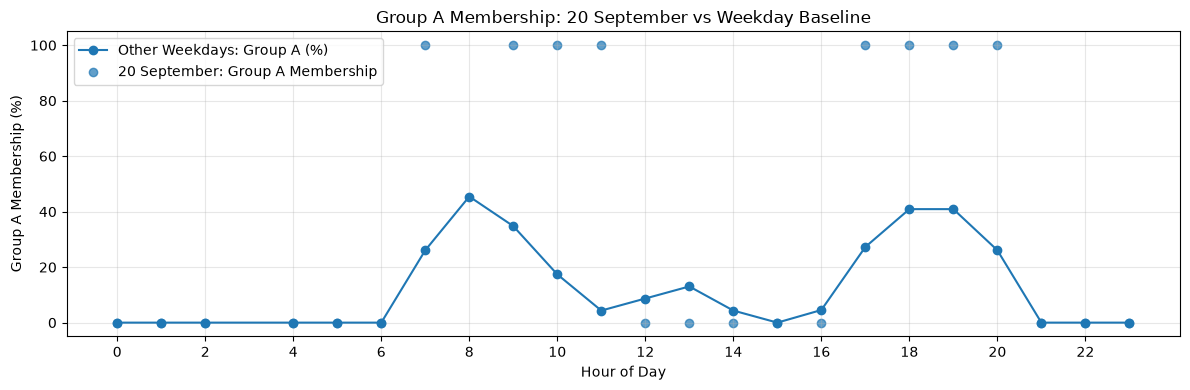

,sample_size
hour_of_day,
0,22
1,22
2,22
4,18
5,23
6,23
7,23
8,22
9,23


In [17]:
# Step 11: Validate the candidate critical moment

import pandas as pd
import matplotlib.pyplot as plt

validation_df = df.copy()

validation_df["timestamp"] = pd.to_datetime(
    validation_df["timestamp"]
)

validation_df["calendar_date"] = (
    validation_df["timestamp"].dt.normalize()
)

validation_df["hour_of_day"] = (
    validation_df["timestamp"].dt.hour
)

validation_df["day_of_week"] = (
    validation_df["timestamp"].dt.dayofweek
)

# Restrict to August–September 2004
validation_df = validation_df[
    (validation_df["timestamp"] >= "2004-08-01") &
    (validation_df["timestamp"] < "2004-10-01")
].copy()

# Keep days with at least 18 valid observations
daily_counts = validation_df.groupby(
    "calendar_date"
).size()

valid_dates = daily_counts[
    daily_counts >= 18
].index

validation_df = validation_df[
    validation_df["calendar_date"].isin(valid_dates)
].copy()

# Candidate critical moment
candidate_date = pd.Timestamp("2004-09-20")

candidate = validation_df[
    validation_df["calendar_date"] == candidate_date
].copy()

# Other weekdays as baseline
baseline = validation_df[
    (validation_df["day_of_week"] < 5) &
    (validation_df["calendar_date"] != candidate_date)
].copy()

print("Candidate observations:", len(candidate))
print("Baseline observations:", len(baseline))

print(
    "Baseline weekdays:",
    baseline["calendar_date"].nunique()
)

# Calculate hourly weekday baseline
baseline_hourly = baseline.groupby(
    "hour_of_day"
).agg(
    co_mean=("co_gt", "mean"),
    nox_mean=("nox_gt", "mean"),
    group_a_pct=("group_a", lambda x: x.mean() * 100),
    sample_size=("co_gt", "size")
)

# Candidate hourly values
candidate_hourly = candidate.set_index(
    "hour_of_day"
).sort_index()

# Compare hourly pollution
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True
)

metrics = [
    ("co_gt", "co_mean", "CO Concentration"),
    ("nox_gt", "nox_mean", "NOx Concentration")
]

for ax, (candidate_col, baseline_col, ylabel) in zip(
    axes, metrics
):

    ax.plot(
        baseline_hourly.index,
        baseline_hourly[baseline_col],
        marker="o",
        label="Other Weekdays (Mean)"
    )

    ax.plot(
        candidate_hourly.index,
        candidate_hourly[candidate_col],
        marker="o",
        label="20 September 2004"
    )

    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_title(
    "20 September vs Other Weekdays"
)

axes[1].set_xlabel("Hour of Day")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

# Compare Group A membership
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    baseline_hourly.index,
    baseline_hourly["group_a_pct"],
    marker="o",
    label="Other Weekdays: Group A (%)"
)

ax.scatter(
    candidate_hourly.index,
    candidate_hourly["group_a"].astype(int) * 100,
    label="20 September: Group A Membership",
    alpha=0.7
)

ax.set_title(
    "Group A Membership: 20 September vs Weekday Baseline"
)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Group A Membership (%)")
ax.set_ylim(-5, 105)
ax.set_xticks(range(0, 24, 2))

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Inspect baseline coverage
display(baseline_hourly[["sample_size"]])

## 13. Pollution Anomaly Assessment

The previous comparison showed that CO and NOx concentrations
on 20 September 2004 were substantially higher than the
average levels observed on other weekdays.

However, a comparison with the mean alone is insufficient
to determine whether these values were unusually high.

To provide a more robust assessment, this section compares
the candidate day's hourly pollution measurements with
the 10th–90th percentile range of other weekdays.

Values above the 90th percentile are treated as exploratory
indicators of unusually elevated pollution.

This analysis helps distinguish ordinary weekday pollution
peaks from potentially unusual pollution episodes.

In [18]:
# Step 12: Assess pollution anomalies on 20 September

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate baseline percentile ranges
baseline_percentiles = baseline.groupby(
    "hour_of_day"
).agg(
    co_p10=("co_gt", lambda x: x.quantile(0.10)),
    co_p50=("co_gt", "median"),
    co_p90=("co_gt", lambda x: x.quantile(0.90)),
    nox_p10=("nox_gt", lambda x: x.quantile(0.10)),
    nox_p50=("nox_gt", "median"),
    nox_p90=("nox_gt", lambda x: x.quantile(0.90))
)

# Compare candidate measurements against the baseline
comparison = candidate_hourly[
    ["co_gt", "nox_gt"]
].join(
    baseline_percentiles,
    how="left"
)

comparison["co_above_p90"] = (
    comparison["co_gt"] > comparison["co_p90"]
)

comparison["nox_above_p90"] = (
    comparison["nox_gt"] > comparison["nox_p90"]
)

comparison["both_above_p90"] = (
    comparison["co_above_p90"] &
    comparison["nox_above_p90"]
)

display(comparison.round(2))

print(
    "Hours with CO above 90th percentile:",
    comparison["co_above_p90"].sum()
)

print(
    "Hours with NOx above 90th percentile:",
    comparison["nox_above_p90"].sum()
)

print(
    "Hours with both pollutants above 90th percentile:",
    comparison["both_above_p90"].sum()
)

print("\nHours with simultaneous exceedances:")

display(
    comparison[
        comparison["both_above_p90"]
    ][["co_gt", "nox_gt", "co_p90", "nox_p90"]].round(2)
)

,co_gt,nox_gt,co_p10,co_p50,co_p90,nox_p10,nox_p50,nox_p90,co_above_p90,nox_above_p90,both_above_p90
hour_of_day,,,,,,,,,,,
0,1.1,100.0,1.00,1.20,1.87,44.5,98.0,235.8,False,False,False
1,0.8,71.0,0.80,1.05,1.30,30.0,82.5,140.5,False,False,False
2,0.7,52.0,0.50,0.65,0.89,18.4,56.0,102.8,False,False,False
4,0.5,57.0,0.27,0.50,0.60,9.8,37.0,83.0,False,False,False
5,0.5,69.0,0.40,0.60,0.78,30.2,60.0,165.2,False,False,False
6,0.9,126.0,0.70,1.10,1.40,43.0,106.0,262.6,False,False,False
7,3.5,376.0,1.44,2.30,4.18,89.6,277.0,641.8,False,False,False
9,5.7,737.0,1.44,2.70,5.28,81.8,239.0,687.4,True,True,True
10,3.5,481.0,1.50,2.20,3.70,93.0,319.0,596.4,False,False,False


Hours with CO above 90th percentile: 7
Hours with NOx above 90th percentile: 5
Hours with both pollutants above 90th percentile: 4

Hours with simultaneous exceedances:


,co_gt,nox_gt,co_p90,nox_p90
hour_of_day,,,,
9,5.7,737.0,5.28,687.4
17,5.0,505.0,4.78,498.8
19,6.5,681.0,5.38,526.9
22,2.0,230.0,1.90,205.0


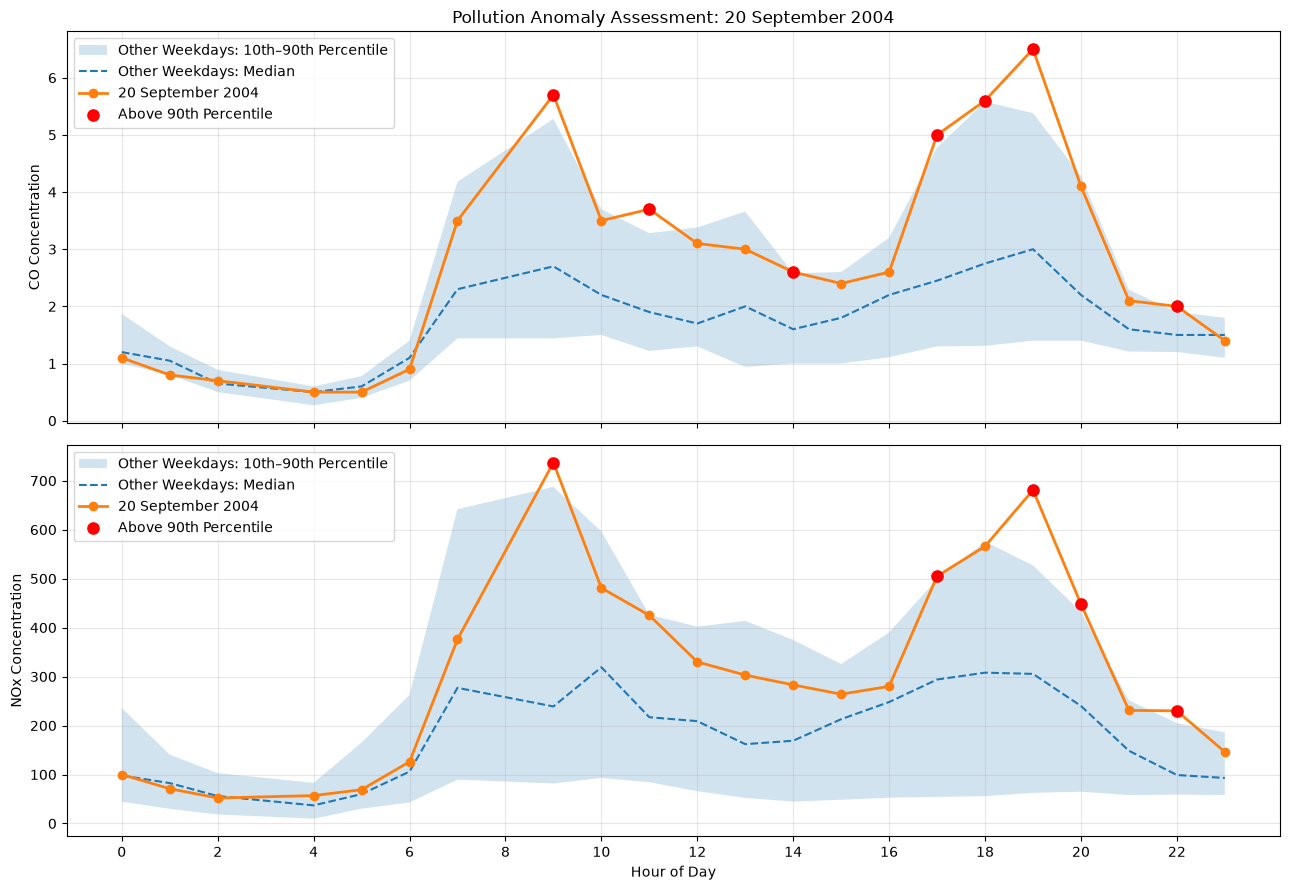

In [19]:
# Visualise the candidate against the weekday reference range

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)

settings = [
    ("co_gt", "co_p10", "co_p50", "co_p90", "CO Concentration"),
    ("nox_gt", "nox_p10", "nox_p50", "nox_p90", "NOx Concentration")
]

for ax, (value, p10, p50, p90, ylabel) in zip(
    axes, settings
):

    ax.fill_between(
        comparison.index,
        comparison[p10],
        comparison[p90],
        alpha=0.2,
        label="Other Weekdays: 10th–90th Percentile"
    )

    ax.plot(
        comparison.index,
        comparison[p50],
        linestyle="--",
        label="Other Weekdays: Median"
    )

    ax.plot(
        comparison.index,
        comparison[value],
        marker="o",
        linewidth=2,
        label="20 September 2004"
    )

    exceedances = comparison[
        comparison[value] > comparison[p90]
    ]

    ax.scatter(
        exceedances.index,
        exceedances[value],
        color="red",
        s=65,
        zorder=5,
        label="Above 90th Percentile"
    )

    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_title(
    "Pollution Anomaly Assessment: 20 September 2004"
)

axes[1].set_xlabel("Hour of Day")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

## 14. Environmental Conditions at the Critical Moment

The anomaly assessment identified several hours on
20 September 2004 when both CO and NOx concentrations
exceeded the 90th percentile of other weekdays.

The evening period from 17:00 to 19:00 is particularly
important because both pollutants increased substantially,
with the highest evening concentrations observed at 19:00.

This section investigates the temperature and relative
humidity conditions associated with the pollution surge.

The objective is to provide environmental context for
the observed transition and establish a basis for the
subsequent what-if scenario.

These relationships are interpreted as associations,
rather than evidence of direct causation.

In [20]:
# Step 13: Environmental conditions around the critical moment

# Ensure timestamp is in datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Select the critical date and surrounding hours
critical_window = df[
    (df["timestamp"] >= "2004-09-20 15:00:00") &
    (df["timestamp"] <= "2004-09-20 21:00:00")
].copy()

critical_window = critical_window.sort_values("timestamp")

# Display pollution, environmental conditions and group membership
display(
    critical_window[
        [
            "timestamp",
            "co_gt",
            "nox_gt",
            "t",
            "rh",
            "group_a"
        ]
    ]
)

,timestamp,co_gt,nox_gt,t,rh,group_a
3217,2004-09-20 15:00:00,2.4,264.0,31.8,27.4,False
3218,2004-09-20 16:00:00,2.6,280.0,34.3,23.2,False
3219,2004-09-20 17:00:00,5.0,505.0,34.1,23.0,True
3220,2004-09-20 18:00:00,5.6,566.0,30.5,29.2,True
3221,2004-09-20 19:00:00,6.5,681.0,28.1,32.4,True
3222,2004-09-20 20:00:00,4.1,448.0,26.5,31.7,True
3223,2004-09-20 21:00:00,2.1,231.0,24.8,33.7,False


### Findings: Environmental Conditions During the Critical Transition

The results identify 17:00 on 20 September 2004 as a
candidate critical transition.

Between 16:00 and 17:00, CO concentration increased
from 2.6 to 5.0 (+92.3%), while NOx concentration
increased from 280 to 505 (+80.4%).

At the same time, the observation changed from
non-membership to membership in Group A.

However, the environmental conditions remained
relatively stable during this transition:

- Temperature decreased slightly from 34.3°C to 34.1°C.
- Relative humidity decreased slightly from 23.2% to 23.0%.

Pollutant concentrations continued to increase until
19:00, when CO reached 6.5 and NOx reached 681.

During this later period, temperature decreased and
relative humidity increased.

These findings indicate that the initial pollution
surge was not accompanied by a substantial immediate
change in temperature or relative humidity.

The observed transition may be associated with
time-dependent pollution patterns, although the
available data do not establish a causal explanation.

Further comparison with environmental conditions
on other weekdays is required before developing
the what-if scenario.

## 15. Environmental Baseline Comparison

To investigate whether the environmental conditions
during the critical transition were unusual, the
temperature and relative humidity recorded on
20 September 2004 are compared with other weekdays
in September 2004.

The comparison is performed at matching hours of
the day to account for typical daily variation.

This analysis provides additional context for the
subsequent what-if scenario.

The comparison is descriptive and does not establish
causal relationships.

In [21]:
# Step 14: Compare environmental conditions with other weekdays

# Select other weekdays in September 2004
baseline = df[
    (df["timestamp"].dt.month == 9) &
    (df["timestamp"].dt.year == 2004) &
    (df["timestamp"].dt.weekday < 5) &
    (df["timestamp"].dt.date != pd.Timestamp("2004-09-20").date())
].copy()

baseline["hour_of_day"] = baseline["timestamp"].dt.hour

# Calculate hourly reference values
environment_baseline = (
    baseline.groupby("hour_of_day")
    .agg(
        sample_size=("t", "count"),
        temperature_median=("t", "median"),
        humidity_median=("rh", "median"),
        co_median=("co_gt", "median"),
        nox_median=("nox_gt", "median")
    )
    .reset_index()
)

# Select the critical day's observations
critical_day = df[
    df["timestamp"].dt.date ==
    pd.Timestamp("2004-09-20").date()
].copy()

critical_day["hour_of_day"] = critical_day["timestamp"].dt.hour

# Compare the critical day with the baseline
comparison = critical_day.merge(
    environment_baseline,
    on="hour_of_day",
    how="left"
)

# Focus on the critical transition period
comparison = comparison[
    comparison["hour_of_day"].between(15, 21)
]

display(
    comparison[
        [
            "hour_of_day",
            "sample_size",
            "t",
            "temperature_median",
            "rh",
            "humidity_median",
            "co_gt",
            "co_median",
            "nox_gt",
            "nox_median"
        ]
    ].round(2)
)

,hour_of_day,sample_size,t,temperature_median,rh,humidity_median,co_gt,co_median,nox_gt,nox_median
13,15,14,31.8,28.95,27.4,32.35,2.4,2.35,264.0,300.0
14,16,14,34.3,30.20,23.2,27.45,2.6,2.80,280.0,319.0
15,17,15,34.1,28.00,23.0,28.80,5.0,3.30,505.0,365.0
16,18,15,30.5,26.50,29.2,37.20,5.6,4.90,566.0,477.0
17,19,16,28.1,25.90,32.4,39.60,6.5,4.70,681.0,475.0
18,20,16,26.5,24.25,31.7,44.55,4.1,3.70,448.0,410.5
19,21,16,24.8,23.25,33.7,47.50,2.1,2.05,231.0,229.0


### Findings: Environmental Baseline Comparison

The environmental baseline comparison provides further
context for the critical transition on 20 September 2004.

At 17:00, CO concentration was 5.0, compared with
a weekday median of 3.3, representing an increase
of approximately 51.5%.

NOx concentration was 505, compared with a weekday
median of 365, representing an increase of
approximately 38.4%.

At the same hour, temperature was 34.1°C, which was
6.1°C above the weekday median, while relative
humidity was 23.0%, which was 5.8 percentage points
below the weekday median.

At 19:00, both pollutants remained substantially
above their corresponding weekday medians.

These findings show that the elevated pollution
concentrations coincided with warmer and drier
conditions relative to the weekday baseline.

However, the initial transition between 16:00
and 17:00 occurred without substantial immediate
changes in temperature or relative humidity.

Therefore, the environmental differences should
be interpreted as associations rather than
evidence of direct causation.

These observations motivate a what-if analysis
examining how projected pollution profiles might
respond to alternative temperature and humidity
conditions.

## 16. Visualising the Environmental Baseline Comparison

This visualisation compares the observed pollution
and environmental conditions on 20 September 2004
with the corresponding hourly weekday medians.

The objective is to identify differences between
the critical event and typical weekday conditions
and to support the selection of plausible
environmental scenarios for further investigation.

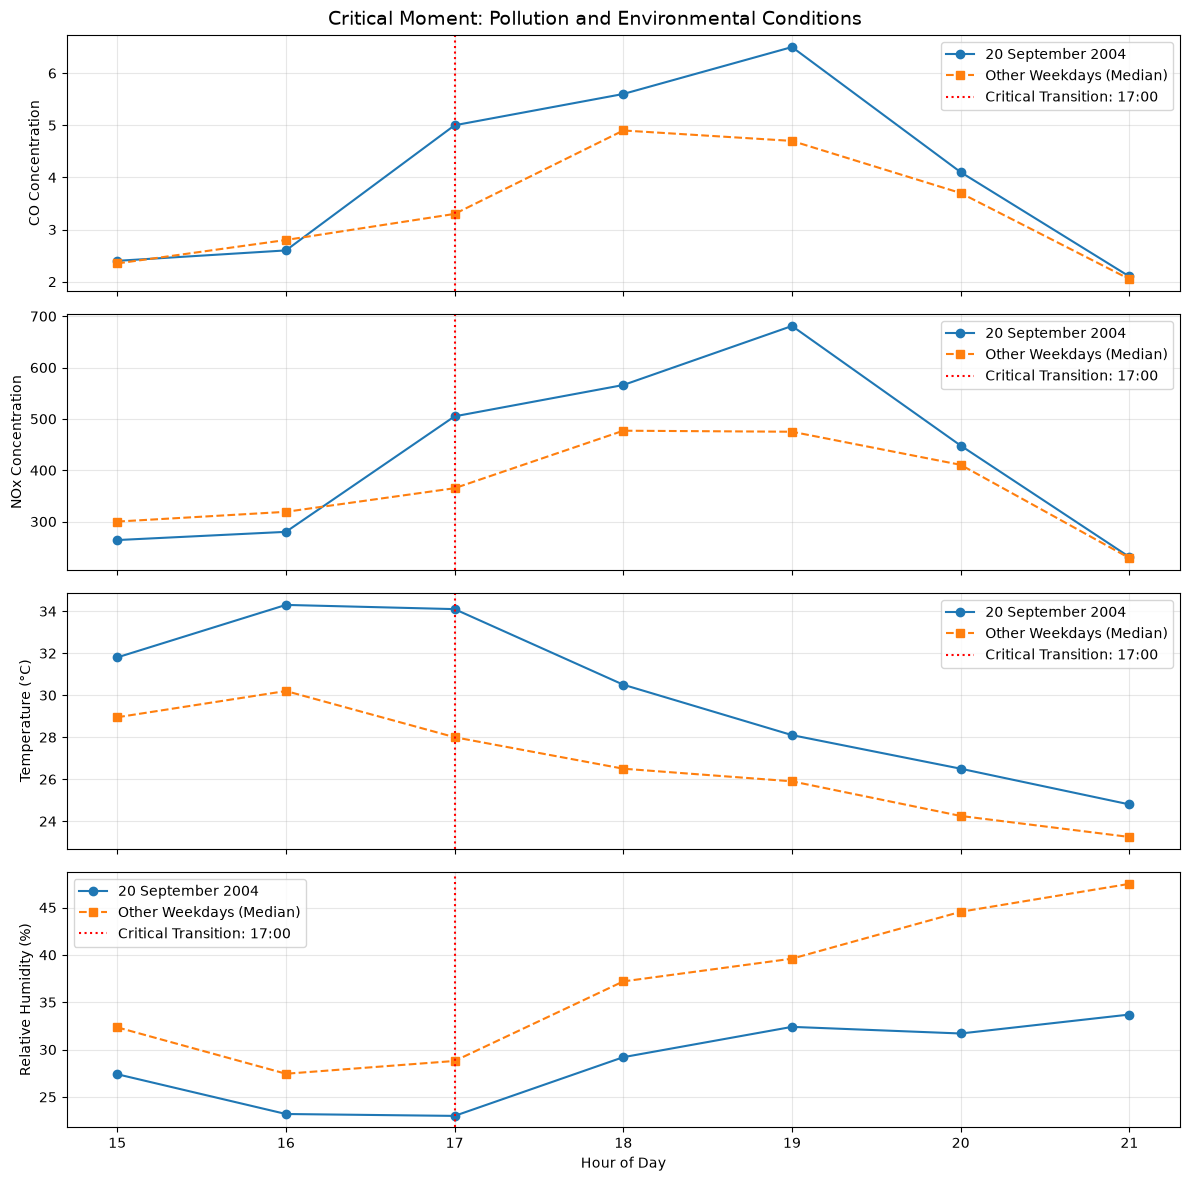

In [22]:
# Step 15: Visualise environmental baseline comparison

fig, axes = plt.subplots(
    4, 1,
    figsize=(12, 12),
    sharex=True
)

variables = [
    ("co_gt", "co_median", "CO Concentration"),
    ("nox_gt", "nox_median", "NOx Concentration"),
    ("t", "temperature_median", "Temperature (°C)"),
    ("rh", "humidity_median", "Relative Humidity (%)")
]

for ax, (actual, baseline_col, label) in zip(axes, variables):

    ax.plot(
        comparison["hour_of_day"],
        comparison[actual],
        marker="o",
        label="20 September 2004"
    )

    ax.plot(
        comparison["hour_of_day"],
        comparison[baseline_col],
        marker="s",
        linestyle="--",
        label="Other Weekdays (Median)"
    )

    ax.axvline(
        x=17,
        color="red",
        linestyle=":",
        label="Critical Transition: 17:00"
    )

    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Hour of Day")

fig.suptitle(
    "Critical Moment: Pollution and Environmental Conditions",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 17. Preparing the What-if Prediction Model

### Objective

The what-if analysis investigates how predicted pollution
concentrations might differ under alternative environmental
conditions during the critical moment.

Temperature and relative humidity are selected as scenario
variables because the observed conditions on 20 September
2004 differed from the typical weekday baseline.

Hour of day and day of week are included to account for
temporal pollution patterns.

Separate predictive models will be developed for CO and NOx.

The models will be evaluated using a chronological
training-test split before their predictions are used
for scenario analysis.

Importantly, the resulting predictions represent
exploratory statistical associations rather than
causal effects of environmental changes.

In [24]:
# Step 16: Prepare data for what-if modelling

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Select variables required for modelling
model_df = df[
    ["timestamp", "co_gt", "nox_gt", "t", "rh"]
].copy()

# Remove observations with missing values
model_df = model_df.dropna()

# Ensure chronological ordering
model_df = model_df.sort_values("timestamp")

# Extract temporal features
model_df["hour_of_day"] = model_df["timestamp"].dt.hour

model_df["day_of_week"] = model_df["timestamp"].dt.dayofweek

# Cyclical encoding of hour
model_df["hour_sin"] = np.sin(
    2 * np.pi * model_df["hour_of_day"] / 24
)

model_df["hour_cos"] = np.cos(
    2 * np.pi * model_df["hour_of_day"] / 24
)

# Define predictors
feature_columns = [
    "t",
    "rh",
    "hour_sin",
    "hour_cos",
    "day_of_week"
]

# Exclude the critical day from model development
critical_date = pd.Timestamp("2004-09-20").date()

model_df["calendar_date"] = model_df["timestamp"].dt.date

training_pool = model_df[
    model_df["calendar_date"] != critical_date
].copy()

print("Total valid observations:", len(model_df))

print(
    "Observations available for model development:",
    len(training_pool)
)

print("\nPredictor variables:")
print(feature_columns)

print("\nData preview:")
display(training_pool.head())

Total valid observations: 6941
Observations available for model development: 6919

Predictor variables:
['t', 'rh', 'hour_sin', 'hour_cos', 'day_of_week']

Data preview:


,timestamp,co_gt,nox_gt,t,rh,hour_of_day,day_of_week,hour_sin,hour_cos,calendar_date
0,2004-03-10 18:00:00,2.6,166.0,13.6,48.9,18,2,-1.000000,-1.836970e-16,2004-03-10
1,2004-03-10 19:00:00,2.0,103.0,13.3,47.7,19,2,-0.965926,2.588190e-01,2004-03-10
2,2004-03-10 20:00:00,2.2,131.0,11.9,54.0,20,2,-0.866025,5.000000e-01,2004-03-10
3,2004-03-10 21:00:00,2.2,172.0,11.0,60.0,21,2,-0.707107,7.071068e-01,2004-03-10
4,2004-03-10 22:00:00,1.6,131.0,11.2,59.6,22,2,-0.500000,8.660254e-01,2004-03-10


## 18. Training and Evaluating the What-if Prediction Models

Two Random Forest regression models estimate CO and NOx concentrations using temperature, relative humidity and temporal features. The selected event date, 20 September 2004, is excluded from model fitting and evaluation.

The remaining observations are sorted chronologically and divided into an 80% training set and a 20% test set. Performance is assessed using Mean Absolute Error (MAE) and the coefficient of determination (R²). A median-based baseline provides an initial comparison, followed by a time-only model to assess whether environmental variables improve prediction.

### Temporal scope and interpretation

Although the test observations occur after the training observations, the training set itself includes records collected after 20 September 2004. Excluding the event date therefore does not make this an event-time forecast.

The models are used for retrospective exploratory analysis. Their results must not be presented as predictions that could have been made using only information available before the event.

Held-out prediction performance does not validate causal responses to changes in temperature or humidity. Before interpreting the scenarios, the model's prediction under unchanged event conditions must also be compared with the actual observation and Group A membership.

In [25]:
# Step 17: Train and evaluate what-if prediction models

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# --------------------------------------------------
# 1. Chronological train-test split
# --------------------------------------------------

training_pool = training_pool.sort_values("timestamp").copy()

split_index = int(len(training_pool) * 0.8)

train_df = training_pool.iloc[:split_index].copy()
test_df = training_pool.iloc[split_index:].copy()

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining period:")
print(train_df["timestamp"].min(), "to", train_df["timestamp"].max())

print("\nTesting period:")
print(test_df["timestamp"].min(), "to", test_df["timestamp"].max())


# --------------------------------------------------
# 2. Define prediction targets
# --------------------------------------------------

targets = {
    "CO": "co_gt",
    "NOx": "nox_gt"
}

models = {}
evaluation_results = []


# --------------------------------------------------
# 3. Train and evaluate each model
# --------------------------------------------------

for target_name, target_column in targets.items():

    print(f"\n--- {target_name} Prediction Model ---")

    y_train = train_df[target_column]
    y_test = test_df[target_column]

    # Random Forest Regression
    rf_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(X_train, y_train)

    rf_predictions = rf_model.predict(X_test)

    # Baseline model
    baseline_model = DummyRegressor(
        strategy="median"
    )

    baseline_model.fit(X_train, y_train)

    baseline_predictions = baseline_model.predict(X_test)

    # Evaluation metrics
    rf_mae = mean_absolute_error(
        y_test, rf_predictions
    )

    rf_r2 = r2_score(
        y_test, rf_predictions
    )

    baseline_mae = mean_absolute_error(
        y_test, baseline_predictions
    )

    baseline_r2 = r2_score(
        y_test, baseline_predictions
    )

    # Save model
    models[target_name] = rf_model

    # Save evaluation results
    evaluation_results.append({
        "Target": target_name,
        "RF_MAE": rf_mae,
        "RF_R2": rf_r2,
        "Baseline_MAE": baseline_mae,
        "Baseline_R2": baseline_r2,
        "MAE_Improvement_%": (
            (baseline_mae - rf_mae)
            / baseline_mae * 100
            if baseline_mae > 0 else np.nan
        )
    })


# --------------------------------------------------
# 4. Display evaluation results
# --------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_results)

print("\nModel Evaluation Results:")

display(evaluation_df.round(3))

Training observations: 5535
Testing observations: 1384

Training period:
2004-03-10 18:00:00 to 2005-01-30 19:00:00

Testing period:
2005-01-30 20:00:00 to 2005-04-04 14:00:00

--- CO Prediction Model ---

--- NOx Prediction Model ---

Model Evaluation Results:


,Target,RF_MAE,RF_R2,Baseline_MAE,Baseline_R2,MAE_Improvement_%
0,CO,0.772,0.404,1.001,-0.006,22.836
1,NOx,132.121,0.145,164.163,-0.517,19.519


## 19. Assessing the Contribution of Environmental Variables

### Objective

Before conducting the what-if analysis, we assess whether
temperature and relative humidity provide additional
predictive information beyond temporal patterns.

Two models are compared:

1. Full Model: Temperature, Relative Humidity, and temporal features.
2. Time-only Model: Temporal features without environmental variables.

Both models use the same chronological training and testing
datasets.

The comparison helps determine whether environmental
variables contribute meaningfully to pollution prediction.

This assessment is important because predictive associations
do not establish causal relationships.

In [26]:
# Step 18: Assess environmental feature contribution

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Define feature groups

full_features = [
    "t",
    "rh",
    "hour_sin",
    "hour_cos",
    "day_of_week"
]

time_features = [
    "hour_sin",
    "hour_cos",
    "day_of_week"
]

feature_sets = {
    "Full Model": full_features,
    "Time-only Model": time_features
}

comparison_results = []

# Compare models for each pollutant

for target_name, target_column in targets.items():

    for model_name, features in feature_sets.items():

        model = RandomForestRegressor(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            train_df[features],
            train_df[target_column]
        )

        predictions = model.predict(
            test_df[features]
        )

        mae = mean_absolute_error(
            test_df[target_column],
            predictions
        )

        r2 = r2_score(
            test_df[target_column],
            predictions
        )

        comparison_results.append({
            "Pollutant": target_name,
            "Model": model_name,
            "MAE": mae,
            "R2": r2
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(3))

,Pollutant,Model,MAE,R2
0,CO,Full Model,0.772,0.404
1,CO,Time-only Model,0.741,0.418
2,NOx,Full Model,132.121,0.145
3,NOx,Time-only Model,108.988,0.280


## 20. What-if Sensitivity Analysis

### Objective

This analysis explores how the prediction model responds to
hypothetical changes in temperature and relative humidity
at the identified critical moment: 20 September 2004, 17:00.

The scenario holds temporal features constant while varying:

- Temperature: -2°C, 0°C, +2°C
- Relative Humidity: -5, 0, +5 percentage points

Predicted CO and NOx concentrations are compared against
the model's original prediction.

The purpose is to assess model sensitivity rather than
establish causal effects.

The previous feature comparison showed that environmental
variables did not improve out-of-sample predictive performance.
Therefore, scenario projections must be interpreted cautiously.

In [27]:
# Step 19: What-if sensitivity analysis

from sklearn.ensemble import RandomForestRegressor
import pandas as pd

# Critical moment
critical_timestamp = pd.Timestamp("2004-09-20 17:00:00")

event_rows = model_df[
    model_df["timestamp"] == critical_timestamp
]

if event_rows.empty:
    raise ValueError("Critical moment not found in model_df.")

event = event_rows.iloc[0]

# Use the same model settings as Step 18
feature_columns = [
    "t",
    "rh",
    "hour_sin",
    "hour_cos",
    "day_of_week"
]

# Train full models
scenario_models = {}

for target_name, target_column in targets.items():

    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        train_df[feature_columns],
        train_df[target_column]
    )

    scenario_models[target_name] = model

# Define hypothetical environmental changes
temperature_changes = [-2, 0, 2]
humidity_changes = [-5, 0, 5]

scenario_results = []

for temp_change in temperature_changes:
    for humidity_change in humidity_changes:

        scenario = event[feature_columns].to_dict()

        scenario["t"] += temp_change
        scenario["rh"] += humidity_change

        scenario_df = pd.DataFrame(
            [scenario],
            columns=feature_columns
        )

        result = {
            "Temperature Change": temp_change,
            "Humidity Change": humidity_change,
            "Scenario Temperature": scenario["t"],
            "Scenario Humidity": scenario["rh"]
        }

        for target_name, model in scenario_models.items():

            prediction = model.predict(scenario_df)[0]

            result[f"Predicted {target_name}"] = prediction

        scenario_results.append(result)

scenario_df = pd.DataFrame(scenario_results)

display(scenario_df.round(2))

,Temperature Change,Humidity Change,Scenario Temperature,Scenario Humidity,Predicted CO,Predicted NOx
0,-2,-5,32.1,18.0,2.70,202.58
1,-2,0,32.1,23.0,2.85,210.42
2,-2,5,32.1,28.0,2.78,205.16
3,0,-5,34.1,18.0,2.63,199.30
4,0,0,34.1,23.0,2.63,188.06
5,0,5,34.1,28.0,2.38,173.94
6,2,-5,36.1,18.0,2.51,170.78
7,2,0,36.1,23.0,2.38,143.31
8,2,5,36.1,28.0,2.20,121.43


## 21. Evaluating What-if Prediction Reliability

### Objective

This section evaluates the reliability of the what-if
prediction model at the identified critical moment.

We compare:

1. Actual pollutant concentrations observed at 17:00.
2. Model predictions under the original environmental conditions.
3. The range of predictions across nine hypothetical scenarios.

This comparison helps determine whether the model can
reliably reproduce the pollution event before its
predictions are used to interpret hypothetical changes.

The analysis distinguishes between observed measurements
and model-based projections.

Predicted changes are interpreted as exploratory model
responses rather than causal effects.

,Pollutant,Actual,Baseline Prediction,Scenario Minimum,Scenario Maximum,Prediction Error,Absolute Percentage Error
0,CO,5.0,2.63,2.20,2.85,-2.37,47.47
1,NOx,505.0,188.06,121.43,210.42,-316.94,62.76


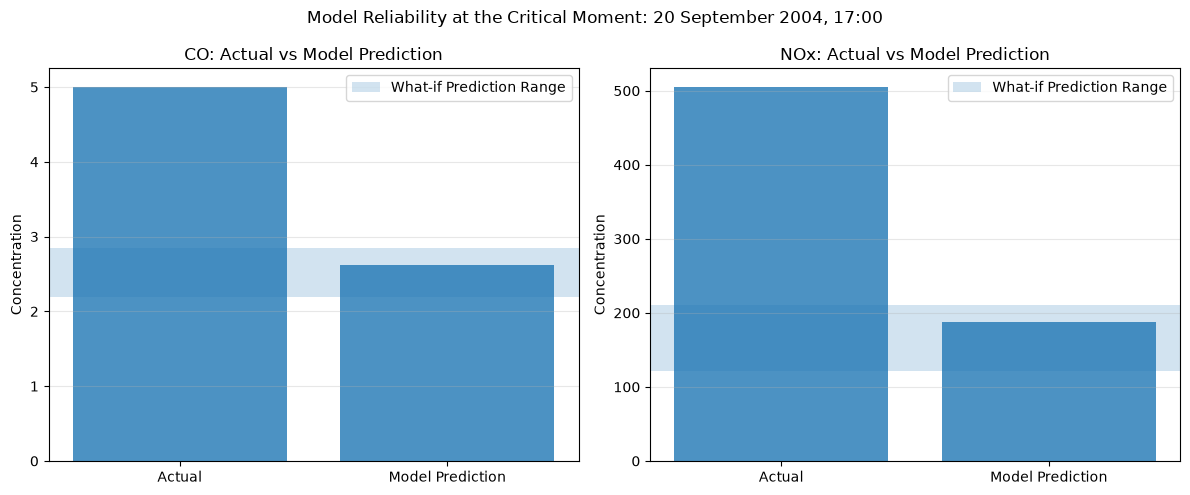

In [28]:
# Step 20: Evaluate what-if prediction reliability

import pandas as pd
import matplotlib.pyplot as plt

# Actual observations at the critical moment
actual_co = event["co_gt"]
actual_nox = event["nox_gt"]

# Original-condition predictions
baseline = scenario_df[
    (scenario_df["Temperature Change"] == 0) &
    (scenario_df["Humidity Change"] == 0)
].iloc[0]

baseline_co = baseline["Predicted CO"]
baseline_nox = baseline["Predicted NOx"]

# Prediction ranges across scenarios
co_min = scenario_df["Predicted CO"].min()
co_max = scenario_df["Predicted CO"].max()

nox_min = scenario_df["Predicted NOx"].min()
nox_max = scenario_df["Predicted NOx"].max()

# Summary table
reliability_df = pd.DataFrame({
    "Pollutant": ["CO", "NOx"],
    "Actual": [actual_co, actual_nox],
    "Baseline Prediction": [
        baseline_co,
        baseline_nox
    ],
    "Scenario Minimum": [
        co_min,
        nox_min
    ],
    "Scenario Maximum": [
        co_max,
        nox_max
    ]
})

reliability_df["Prediction Error"] = (
    reliability_df["Baseline Prediction"] -
    reliability_df["Actual"]
)

reliability_df["Absolute Percentage Error"] = (
    reliability_df["Prediction Error"].abs() /
    reliability_df["Actual"].abs() * 100
)

display(reliability_df.round(2))


# Visual comparison
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

pollutants = [
    ("CO", actual_co, baseline_co, co_min, co_max),
    ("NOx", actual_nox, baseline_nox, nox_min, nox_max)
]

for ax, (name, actual, predicted, low, high) in zip(
    axes, pollutants
):

    ax.bar(
        ["Actual", "Model Prediction"],
        [actual, predicted],
        alpha=0.8
    )

    ax.axhspan(
        low,
        high,
        alpha=0.2,
        label="What-if Prediction Range"
    )

    ax.set_title(f"{name}: Actual vs Model Prediction")

    ax.set_ylabel("Concentration")

    ax.legend()

    ax.grid(
        axis="y",
        alpha=0.3
    )

plt.suptitle(
    "Model Reliability at the Critical Moment: "
    "20 September 2004, 17:00"
)

plt.tight_layout()
plt.show()

## 22. Checking the original-condition prediction

Before interpreting environmental scenarios, the model prediction
under the observed conditions is compared with the actual Group A
membership at 17:00.

If the model already predicts non-membership under unchanged
conditions, non-membership in a hypothetical scenario cannot by
itself demonstrate that the environmental change prevented entry
into Group A.

In [29]:
# Step 21: Check whether what-if predictions preserve Group A

# Group A threshold from Task 1
group_a_threshold = 3.5

# Copy existing scenario results
group_scenario_df = scenario_df.copy()

# Classify predicted Group A membership
group_scenario_df["Predicted Group A"] = (
    group_scenario_df["Predicted CO"] >= group_a_threshold
)

# Calculate changes relative to the model's original prediction
baseline_co = group_scenario_df.loc[
    (group_scenario_df["Temperature Change"] == 0) &
    (group_scenario_df["Humidity Change"] == 0),
    "Predicted CO"
].iloc[0]

group_scenario_df["CO Change from Baseline"] = (
    group_scenario_df["Predicted CO"] - baseline_co
)

# Display results
display(
    group_scenario_df[
        [
            "Temperature Change",
            "Humidity Change",
            "Predicted CO",
            "CO Change from Baseline",
            "Predicted Group A"
        ]
    ].round(3)
)

print("Actual CO:", actual_co)
print("Actual Group A:", actual_co >= group_a_threshold)

print("\nBaseline predicted CO:", round(baseline_co, 3))
print("Baseline predicted Group A:", baseline_co >= group_a_threshold)

print(
    "\nScenarios classified as Group A:",
    group_scenario_df["Predicted Group A"].sum(),
    "out of",
    len(group_scenario_df)
)

,Temperature Change,Humidity Change,Predicted CO,CO Change from Baseline,Predicted Group A
0,-2,-5,2.702,0.076,False
1,-2,0,2.849,0.222,False
2,-2,5,2.776,0.149,False
3,0,-5,2.631,0.005,False
4,0,0,2.627,0.000,False
5,0,5,2.380,-0.246,False
6,2,-5,2.510,-0.117,False
7,2,0,2.381,-0.246,False
8,2,5,2.196,-0.431,False


Actual CO: 5.0
Actual Group A: True

Baseline predicted CO: 2.627
Baseline predicted Group A: False

Scenarios classified as Group A: 0 out of 9


## 23. Testing whether scenarios avoid the observed membership change

At 16:00, the observation belonged to Group C but not Group A.
At 17:00, it belonged to both A and C.

The scenario target is therefore to avoid entry into Group A
while retaining Group C membership.

Baseline-anchored CO estimates are used only as an exploratory
sensitivity calculation. Matching the observed starting value
does not validate the model's response to environmental changes.

In [30]:
# Test avoidance of Group A entry while retaining Group C.
# Requires the scenario results and group_scenario_df above.

# Read the actual event value instead of hard-coding 5.0.
event_time = pd.Timestamp("2004-09-20 17:00:00")

observed_event = df.loc[
    pd.to_datetime(df["timestamp"]) == event_time
]

assert len(observed_event) == 1, "Expected one event observation."

actual_co = float(observed_event.iloc[0]["co_gt"])
group_a_threshold = 3.5

anchored_df = group_scenario_df.copy()

# Identify the unchanged environmental scenario.
unchanged_mask = (
    (anchored_df["Temperature Change"] == 0)
    & (anchored_df["Humidity Change"] == 0)
)

assert unchanged_mask.sum() == 1, (
    "Expected exactly one unchanged scenario."
)

baseline_co = float(
    anchored_df.loc[unchanged_mask, "Predicted CO"].iloc[0]
)

# Preserve the existing column names used by later cells.
anchored_df["Predicted Change"] = (
    anchored_df["Predicted CO"] - baseline_co
)

anchored_df["Anchored CO"] = (
    actual_co + anchored_df["Predicted Change"]
)

anchored_df["Anchored Group A"] = (
    anchored_df["Anchored CO"] >= group_a_threshold
)

# Group C depends directly on the scenario's T and RH.
anchored_df["Scenario Group C"] = (
    (anchored_df["Scenario Temperature"] >= 26)
    & (anchored_df["Scenario Humidity"] <= 35)
)

# Correct direction: avoid A while retaining C.
anchored_df["Avoided A Entry"] = (
    ~anchored_df["Anchored Group A"]
)

anchored_df["Target A/C State Met"] = (
    anchored_df["Avoided A Entry"]
    & anchored_df["Scenario Group C"]
)

# Separate actual environmental changes from the unchanged baseline.
changed_mask = ~unchanged_mask

display(
    anchored_df[[
        "Temperature Change",
        "Humidity Change",
        "Scenario Temperature",
        "Scenario Humidity",
        "Predicted CO",
        "Predicted Change",
        "Anchored CO",
        "Avoided A Entry",
        "Scenario Group C",
        "Target A/C State Met"
    ]].round(3)
)

print(f"Observed event CO: {actual_co:.3f} mg/m³")
print(f"Original-condition prediction: {baseline_co:.3f} mg/m³")

print(
    "Direct model reproduces observed Group A membership:",
    (baseline_co >= group_a_threshold)
    == (actual_co >= group_a_threshold)
)

print(
    "Anchored scenarios meeting the A/C target:",
    f"{int(anchored_df['Target A/C State Met'].sum())}"
    f"/{len(anchored_df)}"
)

print(
    "Changed environmental scenarios meeting the A/C target:",
    f"{int(anchored_df.loc[changed_mask, 'Target A/C State Met'].sum())}"
    f"/{int(changed_mask.sum())}"
)

print(
    "\nAnchoring fixes the starting value by construction; "
    "it does not validate environmental effects."
)

,Temperature Change,Humidity Change,Scenario Temperature,Scenario Humidity,Predicted CO,Predicted Change,Anchored CO,Avoided A Entry,Scenario Group C,Target A/C State Met
0,-2,-5,32.1,18.0,2.702,0.076,5.076,False,True,False
1,-2,0,32.1,23.0,2.849,0.222,5.222,False,True,False
2,-2,5,32.1,28.0,2.776,0.149,5.149,False,True,False
3,0,-5,34.1,18.0,2.631,0.005,5.005,False,True,False
4,0,0,34.1,23.0,2.627,0.000,5.000,False,True,False
5,0,5,34.1,28.0,2.380,-0.246,4.754,False,True,False
6,2,-5,36.1,18.0,2.510,-0.117,4.883,False,True,False
7,2,0,36.1,23.0,2.381,-0.246,4.754,False,True,False
8,2,5,36.1,28.0,2.196,-0.431,4.569,False,True,False


Observed event CO: 5.000 mg/m³
Original-condition prediction: 2.627 mg/m³
Direct model reproduces observed Group A membership: False
Anchored scenarios meeting the A/C target: 0/9
Changed environmental scenarios meeting the A/C target: 0/8

Anchoring fixes the starting value by construction; it does not validate environmental effects.


In [31]:
# Explore historically observed T/RH pairs.
# This is a retrospective sensitivity check, not causal validation.
# Requires scenario_models from the existing modelling section.

history_check = df.copy()
history_check["timestamp"] = pd.to_datetime(
    history_check["timestamp"]
)

event_timestamp = pd.Timestamp("2004-09-20 17:00")

event_record = history_check.loc[
    history_check["timestamp"] == event_timestamp
].iloc[0]

# Use only environmental pairs observed before the event day.
# Match hour and weekday type, and retain Group C conditions.
historical_pairs = history_check.loc[
    (history_check["timestamp"] < event_timestamp.normalize())
    & (history_check["timestamp"].dt.hour == 17)
    & (history_check["timestamp"].dt.dayofweek < 5)
    & (history_check["t"] >= 26)
    & (history_check["rh"] <= 35)
].copy()

scenario_features = [
    "t", "rh", "hour_sin", "hour_cos", "day_of_week"
]

event_input = pd.DataFrame([{
    "t": float(event_record["t"]),
    "rh": float(event_record["rh"]),
    "hour_sin": np.sin(2 * np.pi * 17 / 24),
    "hour_cos": np.cos(2 * np.pi * 17 / 24),
    "day_of_week": event_timestamp.dayofweek
}])[scenario_features]

co_model = scenario_models["CO"]
original_prediction = float(co_model.predict(event_input)[0])

historical_inputs = pd.concat(
    [event_input] * len(historical_pairs),
    ignore_index=True
)

historical_inputs["t"] = historical_pairs["t"].to_numpy()
historical_inputs["rh"] = historical_pairs["rh"].to_numpy()

historical_pairs["direct_prediction"] = co_model.predict(
    historical_inputs
)

historical_pairs["anchored_co"] = (
    float(event_record["co_gt"])
    + historical_pairs["direct_prediction"]
    - original_prediction
)

historical_pairs["target_met"] = (
    historical_pairs["anchored_co"] < 3.5
)

# All selected environmental pairs retain C by construction.
historical_pairs["source_time"] = (
    historical_pairs["timestamp"].dt.strftime("%Y-%m-%d %H:%M")
)

import plotly.express as px

support_fig = px.scatter(
    historical_pairs,
    x="t",
    y="rh",
    color="anchored_co",
    hover_name="source_time",
    hover_data={
        "co_gt": ":.2f",
        "direct_prediction": ":.3f",
        "anchored_co": ":.3f",
        "target_met": True
    },
    labels={
        "t": "Scenario temperature (°C)",
        "rh": "Scenario relative humidity (%)",
        "co_gt": "CO observed on the historical date",
        "direct_prediction": "Direct model CO",
        "anchored_co": "Anchored CO (mg/m³)",
        "target_met": "Avoids A while retaining C"
    },
    color_continuous_scale="Viridis",
    title=(
        "Historically observed environmental scenarios"
        "<br><sup>Event time features fixed; "
        "all pairs retain C; avoidance of A requires CO < 3.5</sup>"
    )
)

support_fig.update_traces(marker=dict(size=10))
support_fig.update_layout(template="plotly_white", height=550)
support_fig.show()

print("Historical observations:", len(historical_pairs))
print(
    "Anchored CO range:",
    round(historical_pairs["anchored_co"].min(), 3),
    "to",
    round(historical_pairs["anchored_co"].max(), 3),
    "mg/m³"
)
print(
    "Environmental pairs meeting the target:",
    int(historical_pairs["target_met"].sum())
)

Historical observations: 61
Anchored CO range: 4.5 to 5.636 mg/m³
Environmental pairs meeting the target: 0


## 24. Assessing Historical Support for What-if Scenarios

### Objective

This section examines whether environmental conditions similar to the nine tested scenarios occur elsewhere in the dataset. It provides descriptive context for the Group A analysis rather than independent validation of the scenario predictions.

### Comparison pool and method

The comparison pool contains 215 complete weekday observations at 17:00, excluding 20 September 2004. It includes observations from both before and after the event date. Here, “historical” refers to records in the available dataset, not exclusively to information available before the event.

For each scenario, matching observations are selected within:

- ±2°C of the scenario temperature;
- ±5 percentage points of the scenario relative humidity.

The analysis reports the number of matching observations, their mean observed CO concentration and the percentage meeting the Group A rule, CO ≥ 3.5 mg/m³. Matching sets may overlap across scenarios.

This pool is distinct from the separate analysis of 61 environmental pairs observed before the event day. The two analyses use different selection criteria and must not be treated as the same evidence.

### Interpretation

Comparable observations indicate that similar environmental conditions occur in the dataset. They do not establish what CO would have been at the selected event under those conditions.

In particular, a mean CO concentration below 3.5 mg/m³ does not imply that every matched observation falls outside Group A. These comparisons cannot demonstrate that an environmental adjustment would have prevented entry into Group A.

In [32]:
# Step 23: Assess historical support for what-if scenarios

import pandas as pd

# Critical moment
critical_hour = 17
critical_temperature = 34.1
critical_humidity = 23.0

# Use historical observations, excluding the critical date
historical_df = model_df[
    (model_df["hour_of_day"] == critical_hour) &
    (model_df["day_of_week"] < 5) &
    (model_df["calendar_date"] != critical_date)
].copy()

# Matching tolerances
temperature_tolerance = 2.0
humidity_tolerance = 5.0

support_results = []

for _, scenario in anchored_df.iterrows():

    scenario_t = (
        critical_temperature +
        scenario["Temperature Change"]
    )

    scenario_rh = (
        critical_humidity +
        scenario["Humidity Change"]
    )

    # Find observations with similar conditions
    similar = historical_df[
        (historical_df["t"].between(
            scenario_t - temperature_tolerance,
            scenario_t + temperature_tolerance
        )) &
        (historical_df["rh"].between(
            scenario_rh - humidity_tolerance,
            scenario_rh + humidity_tolerance
        ))
    ]

    support_results.append({
        "Temperature Change": scenario["Temperature Change"],
        "Humidity Change": scenario["Humidity Change"],
        "Scenario Temperature": scenario_t,
        "Scenario Humidity": scenario_rh,
        "Similar Observations": len(similar),
        "Observed Mean CO": (
            similar["co_gt"].mean()
            if len(similar) > 0 else float("nan")
        ),
        "Observed Group A (%)": (
            100 * (similar["co_gt"] >= 3.5).mean()
            if len(similar) > 0 else float("nan")
        )
    })

support_df = pd.DataFrame(support_results)

display(support_df.round(2))

print(
    "Total historical weekday observations at 17:00:",
    len(historical_df)
)

print(
    "Scenarios with at least 10 similar observations:",
    (support_df["Similar Observations"] >= 10).sum(),
    "out of",
    len(support_df)
)

,Temperature Change,Humidity Change,Scenario Temperature,Scenario Humidity,Similar Observations,Observed Mean CO,Observed Group A (%)
0,-2,-5,32.1,18.0,8,2.81,12.50
1,-2,0,32.1,23.0,12,2.83,25.00
2,-2,5,32.1,28.0,9,3.18,44.44
3,0,-5,34.1,18.0,10,2.66,0.00
4,0,0,34.1,23.0,13,2.78,15.38
5,0,5,34.1,28.0,10,2.86,30.00
6,2,-5,36.1,18.0,13,2.65,15.38
7,2,0,36.1,23.0,13,2.54,15.38
8,2,5,36.1,28.0,8,2.38,12.50


Total historical weekday observations at 17:00: 215
Scenarios with at least 10 similar observations: 6 out of 9


### Findings and Interpretation

From the 215-record comparison pool, each of the nine environmental settings has between 8 and 13 matching observations. Six settings have at least 10 matches. These small, potentially overlapping samples provide limited descriptive context.

The observed proportion belonging to Group A ranges from 0% to 44.44% across the matching sets. Although the corresponding mean CO concentrations are below the Group A threshold, those means do not establish non-membership for every observation. Even a matching set with no Group A observations cannot demonstrate that the selected event would have avoided Group A under an environmental adjustment.

The relevant objective is to avoid the observed entry into Group A while retaining Group C. The historical comparisons do not establish that this objective would be achieved.

The direct model already predicts non-membership in Group A under unchanged event conditions, despite the observed membership. Its below-threshold scenario predictions therefore cannot be treated as evidence of successful prevention. The baseline-anchored estimates remain above the Group A threshold for all nine settings, so none of the eight changed settings meets the avoidance target.

### Limitations

The comparison pool includes observations after the event and is not restricted to an independent validation set. Matching temperature, humidity and hour does not control for emissions, seasonal differences or other unmeasured influences.

The limited sample sizes, overlapping matching sets and substantial prediction error at the event restrict the strength of the conclusions. The historical comparisons do not validate the anchoring assumption or establish causal effects.

The supported conclusion is that the tested approach has not demonstrated a reliable environmental scenario that avoids Group A entry while retaining Group C. This does not prove that all possible alternatives would fail.

## 25. Interactive What-if Visualisation

### Objective

To develop an interactive visualisation that allows users to explore
how hypothetical changes in temperature and relative humidity are
associated with different model-based CO estimates at the identified
critical moment.

### Visualisation Design

The interactive visualisation compares three types of information:

1. Direct model predictions under hypothetical environmental conditions.
2. Baseline-anchored sensitivity estimates.
3. Mean CO concentrations observed under similar historical conditions.

Users can select different humidity changes and compare the corresponding
temperature scenarios.

A reference line indicates the CO threshold used for Group A classification.

### Interpretation Considerations

The baseline-anchored estimates represent hypothetical changes relative
to the observed critical moment, rather than independently validated
forecasts.

Historical observations provide descriptive context but do not establish
causal effects.

The visualisation is intended to support exploratory sensitivity analysis,
not to demonstrate that changing temperature or humidity would necessarily
prevent or preserve a pollution event.

In [34]:
# Step 24: Interactive What-if Visualisation

import pandas as pd
import plotly.graph_objects as go

# --------------------------------------------------
# 1. Combine results from previous analyses
# --------------------------------------------------

viz_df = scenario_df[
    [
        "Temperature Change",
        "Humidity Change",
        "Predicted CO"
    ]
].merge(
    anchored_df[
        [
            "Temperature Change",
            "Humidity Change",
            "Anchored CO",
            "Anchored Group A"
        ]
    ],
    on=["Temperature Change", "Humidity Change"],
    validate="one_to_one"
).merge(
    support_df[
        [
            "Temperature Change",
            "Humidity Change",
            "Similar Observations",
            "Observed Mean CO",
            "Observed Group A (%)"
        ]
    ],
    on=["Temperature Change", "Humidity Change"],
    validate="one_to_one"
)

viz_df = viz_df.sort_values(
    ["Humidity Change", "Temperature Change"]
)

display(viz_df.round(2))


# --------------------------------------------------
# 2. Create interactive figure
# --------------------------------------------------

fig = go.Figure()

humidity_levels = [-5, 0, 5]

series = [
    ("Predicted CO", "Direct Model Prediction"),
    ("Anchored CO", "Baseline-Anchored Estimate"),
    ("Observed Mean CO", "Historical Observed Mean")
]

for humidity in humidity_levels:

    subset = viz_df[
        viz_df["Humidity Change"] == humidity
    ].sort_values("Temperature Change")

    hover_text = []

    for _, row in subset.iterrows():

        hover_text.append(
            f"Temperature change: {row['Temperature Change']:+.0f}°C"
            f"<br>Humidity change: {row['Humidity Change']:+.0f} pp"
            f"<br>Direct prediction: {row['Predicted CO']:.2f}"
            f"<br>Anchored estimate: {row['Anchored CO']:.2f}"
            f"<br>Historical mean CO: {row['Observed Mean CO']:.2f}"
            f"<br>Similar observations: {int(row['Similar Observations'])}"
            f"<br>Historical Group A: {row['Observed Group A (%)']:.1f}%"
        )

    for column, label in series:

        fig.add_trace(
            go.Scatter(
                x=subset["Temperature Change"],
                y=subset[column],
                mode="lines+markers",
                name=label,
                text=hover_text,
                hovertemplate="%{text}<extra>%{fullData.name}</extra>",
                visible=(humidity == 0),
                line=dict(width=2),
                marker=dict(size=10)
            )
        )


# --------------------------------------------------
# 3. Add reference lines
# --------------------------------------------------

fig.add_hline(
    y=3.5,
    line_dash="dash",
    line_color="red",
    annotation_text="Group A CO threshold: 3.5"
)

fig.add_hline(
    y=5.0,
    line_dash="dot",
    line_color="gray",
    annotation_text="Actual CO at 17:00: 5.0"
)


# --------------------------------------------------
# 4. Add humidity selection dropdown
# --------------------------------------------------

buttons = []

for i, humidity in enumerate(humidity_levels):

    visibility = [
        (j // len(series)) == i
        for j in range(len(humidity_levels) * len(series))
    ]

    buttons.append(
        dict(
            label=f"Humidity {humidity:+d} pp",
            method="update",
            args=[
                {"visible": visibility},
                {
                    "title": (
                        "What-if CO Sensitivity Analysis"
                        f"<br><sup>Humidity change: {humidity:+d} "
                        "percentage points</sup>"
                    )
                }
            ]
        )
    )

fig.update_layout(
    title=(
        "What-if CO Sensitivity Analysis"
        "<br><sup>Humidity change: 0 percentage points</sup>"
    ),
    xaxis_title="Temperature Change (°C)",
    yaxis_title="CO Concentration",
    xaxis=dict(
        tickmode="array",
        tickvals=[-2, 0, 2]
    ),
    updatemenus=[
        dict(
            buttons=buttons,
            direction="down",
            showactive=True,
            x=0.02,
            y=1.10
        )
    ],
    hovermode="closest",
    template="plotly_white",
    height=650,
    margin=dict(t=150),
    legend=dict(
        orientation="h",
        y=-0.2
    )
)

fig.show()

,Temperature Change,Humidity Change,Predicted CO,Anchored CO,Anchored Group A,Similar Observations,Observed Mean CO,Observed Group A (%)
0,-2,-5,2.70,5.08,True,8,2.81,12.50
3,0,-5,2.63,5.00,True,10,2.66,0.00
6,2,-5,2.51,4.88,True,13,2.65,15.38
1,-2,0,2.85,5.22,True,12,2.83,25.00
4,0,0,2.63,5.00,True,13,2.78,15.38
7,2,0,2.38,4.75,True,13,2.54,15.38
2,-2,5,2.78,5.15,True,9,3.18,44.44
5,0,5,2.38,4.75,True,10,2.86,30.00
8,2,5,2.20,4.57,True,8,2.38,12.50


### Interpretation of the Group A scenario analysis

The observed transition on 20 September was from Group C at 16:00 to overlapping Groups A and C at 17:00. The scenario objective is therefore to avoid entry into A while retaining C.

Under unchanged environmental conditions, the model predicts CO of approximately 2.63 mg/m³, compared with the observed 5.0 mg/m³. It already misclassifies the event as outside Group A. Consequently, direct scenario predictions below 3.5 mg/m³ do not demonstrate that an environmental adjustment prevented entry into A.

All nine anchored settings, including the unchanged baseline, remain above the Group A threshold, with CO estimates of approximately 4.57–5.22 mg/m³. None of the eight changed settings meets the avoidance target. The separate check using 61 environmental pairs observed before the event day also finds no successful anchored scenario.

The full models do not outperform the time-only models on the held-out comparison. Moreover, model training includes observations after the event date. These are retrospective sensitivity calculations, not forecasts available on 20 September.

The 215-record comparison pool used for the historical-mean curves includes observations after the event and is distinct from the 61 pre-event environmental pairs. A historical mean below the threshold does not establish non-membership for every matched observation or validate a scenario for this event.

The tested scenarios therefore do not provide reliable evidence of avoiding Group A entry. This is a limitation of the tested approach, not proof that every possible environmental alternative would fail.

## 26. Visual investigation of a change in Group C membership

Group C uses the existing selection rule **temperature ≥ 26°C and relative humidity ≤ 35%**. These thresholds remain fixed throughout this analysis.

The shared web tool's monthly views show 94 Group C observations in September 2004 and none in October among the complete records. This provides a visual lead for closer inspection, rather than establishing an exact transition date. Empty cells in the monthly attribute profile indicate that no Group C members are available for summarisation; they do not represent zero-valued environmental measurements.

The following interactive heatmaps examine 25 September–10 October at hourly resolution. Identical row and column arrangements allow Group C membership, temperature and relative humidity to be compared at matching dates and hours. Numerical labels and hover details support inspection of the underlying values. Grey cells represent unavailable observations and are excluded from membership comparisons.

The focused comparison uses **14:00–17:00 on 29 and 30 September**, for which all four corresponding hours are available on both days. Comparing matching hours reduces differences in time-of-day composition, although it does not control for all other differences between days.

In [37]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Use the same cleaned data and fixed Group C definition.
c_view = df.copy()
c_view["timestamp"] = pd.to_datetime(c_view["timestamp"])

c_view = c_view[
    c_view["timestamp"].between(
        "2004-09-25 00:00", "2004-10-10 23:59"
    )
    & c_view["timestamp"].dt.hour.between(11, 17)
].copy()

assert not c_view["timestamp"].duplicated().any(), \
    "Duplicate timestamps found; check the data before plotting."

c_view["date"] = c_view["timestamp"].dt.strftime("%Y-%m-%d")
c_view["hour"] = c_view["timestamp"].dt.hour

valid_env = c_view[["t", "rh"]].notna().all(axis=1)
c_view["in_c"] = np.where(
    valid_env,
    ((c_view["t"] >= 26) & (c_view["rh"] <= 35)).astype(float),
    np.nan
)

dates = pd.date_range(
    "2004-09-25", "2004-10-10"
).strftime("%Y-%m-%d").tolist()
hours = list(range(11, 18))
hour_labels = [f"{h:02d}:00" for h in hours]

def date_hour_grid(column):
    return (
        c_view.pivot(index="date", columns="hour", values=column)
        .reindex(index=dates, columns=hours)
    )

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=[
        "Group C: 1 = member, 0 = non-member",
        "Temperature (°C): C requires ≥ 26",
        "Relative humidity (%): C requires ≤ 35"
    ],
    horizontal_spacing=0.07
)

panels = [
    ("in_c", [[0, "#eef2f6"], [1, "#16a878"]], 0, 1),
    ("t", "YlOrRd", None, None),
    ("rh", "YlGnBu", None, None)
]

for col, (field, colours, low, high) in enumerate(panels, start=1):
    grid = date_hour_grid(field)

    fig.add_trace(
        go.Heatmap(
            x=hour_labels,
            y=dates,
            z=grid.to_numpy(),
            colorscale=colours,
            zmin=low,
            zmax=high,
            showscale=False,
            texttemplate="%{z:.0f}" if field == "in_c" else "%{z:.1f}",
            textfont={"size": 10},
            xgap=2,
            ygap=2,
            hoverongaps=False,
            hovertemplate=(
                "Date: %{y}<br>Hour: %{x}<br>"
                + field + ": %{z:.2f}<extra></extra>"
            )
        ),
        row=1, col=col
    )

fig.update_yaxes(autorange="reversed", type="category")
fig.update_xaxes(
    type="category",
    side="bottom",
    tickfont=dict(size=10),
    tickangle=0,
    automargin=True
)

short_titles = [
    "Group C membership (0 / 1)",
    "Temperature (°C)",
    "Relative humidity (%)"
]

for annotation, title in zip(fig.layout.annotations, short_titles):
    annotation.update(
        text=title,
        font=dict(size=13),
        yshift=12
    )

fig.update_yaxes(tickfont=dict(size=10), automargin=True)
fig.update_yaxes(showticklabels=False, row=1, col=2)
fig.update_yaxes(showticklabels=False, row=1, col=3)
fig.update_layout(
    title=(
        "Inspecting the disappearance of Group C"
        "<br><sup>Fixed rule: T ≥ 26°C AND RH ≤ 35%; "
        "grey cells = unavailable observations</sup>"
    ),
    height=500,
    width=1000,
    plot_bgcolor="#cbd2d9",
    paper_bgcolor="white",
    margin=dict(t=120, b=40)
)
group_c_evidence_fig = go.Figure(fig)
fig.show()

# Inspect the same four hours on both days.
comparison = c_view[
    c_view["date"].isin(["2004-09-29", "2004-09-30"])
    & c_view["hour"].between(14, 17)
][["timestamp", "t", "rh", "co_gt", "in_c"]].copy()

display(comparison.sort_values("timestamp").reset_index(drop=True))

,timestamp,t,rh,co_gt,in_c
0,2004-09-29 14:00:00,26.4,28.5,2.4,1.0
1,2004-09-29 15:00:00,27.7,25.1,2.8,1.0
2,2004-09-29 16:00:00,28.6,23.2,3.6,1.0
3,2004-09-29 17:00:00,27.2,26.3,4.0,1.0
4,2004-09-30 14:00:00,25.6,43.4,2.2,0.0
5,2004-09-30 15:00:00,26.1,42.6,2.8,0.0
6,2004-09-30 16:00:00,25.8,44.8,3.9,0.0
7,2004-09-30 17:00:00,25.4,47.9,6.5,0.0


## 27. Critical-period evidence and environmental scenarios

The hourly views reveal a change from **4/4 Group C members on 29 September to 0/4 on 30 September**, comparing 14:00–17:00 on both days. This identifies a short-period change in membership rather than a precisely observed instantaneous transition.

On 29 September, these hours have temperatures of 26.4–28.6°C and relative humidity of 23.2–28.5%, satisfying both Group C conditions. On 30 September, relative humidity rises to 42.6–47.9%, exceeding the 35% threshold at every selected hour. Temperature is also below 26°C at 14:00, 16:00 and 17:00. At 15:00, temperature remains above the threshold at 26.1°C, so humidity alone excludes that observation from Group C.

This evidence motivates three environmental scenarios for the selected 30 September observations:

1. Replace temperature only with the previous day's value at the matching hour.
2. Replace relative humidity only with the previous day's value at the matching hour.
3. Replace both temperature and relative humidity with the previous day's matching pair.

The timestamp, other measured attributes and Group C thresholds remain unchanged. The joint scenario uses temperature–humidity pairs that were actually observed on 29 September. The single-variable scenarios combine an earlier value with an unchanged 30 September value; these hybrid pairs are not necessarily historically observed.

The scenario heatmap compares all alternatives using the same hour columns and membership colours. Hover details show the substituted values and their changes from the actual conditions. The objective is to determine which tested scenario would retain Group C membership under the fixed rule.

In [38]:
# Compare exactly the same hours on the two days.
source = df.copy()
source["timestamp"] = pd.to_datetime(source["timestamp"])
source = source.set_index("timestamp").sort_index()

hours = [14, 15, 16, 17]
before_times = pd.to_datetime([
    f"2004-09-29 {h:02d}:00" for h in hours
])
event_times = pd.to_datetime([
    f"2004-09-30 {h:02d}:00" for h in hours
])

assert source.index.is_unique, "Please check duplicate timestamps."

before = source.reindex(before_times)
event = source.reindex(event_times)

assert before[["t", "rh"]].notna().all().all()
assert event[["t", "rh"]].notna().all().all()

# Each scenario starts from September 30.
# Only the named environmental attributes are replaced.
scenario_specs = [
    ("Actual 30 Sep", False, False),
    ("Restore T only", True, False),
    ("Restore RH only", False, True),
    ("Restore T + RH", True, True)
]

scenario_tables = []

for name, replace_t, replace_rh in scenario_specs:
    scenario = event.copy()

    if replace_t:
        scenario["t"] = before["t"].to_numpy()
    if replace_rh:
        scenario["rh"] = before["rh"].to_numpy()

    # Keep the original Group C rule unchanged.
    scenario["in_c"] = (
        (scenario["t"] >= 26) & (scenario["rh"] <= 35)
    )
    # Keep stored group labels consistent with scenario conditions.
    scenario["group_c"] = scenario["in_c"]
    scenario["group_d"] = scenario["t"] <= 10
    scenario["scenario"] = name
    scenario["hour"] = [f"{h:02d}:00" for h in hours]
    scenario["delta_t"] = (
        scenario["t"].to_numpy() - event["t"].to_numpy()
    )
    scenario["delta_rh"] = (
        scenario["rh"].to_numpy() - event["rh"].to_numpy()
    )

    scenario_tables.append(scenario.reset_index())

whatif_c = pd.concat(scenario_tables, ignore_index=True)
scenario_names = [item[0] for item in scenario_specs]
hour_labels = [f"{h:02d}:00" for h in hours]

def scenario_grid(column):
    return (
        whatif_c.pivot(
            index="scenario", columns="hour", values=column
        )
        .reindex(index=scenario_names, columns=hour_labels)
        .to_numpy()
    )

membership = scenario_grid("in_c").astype(int)
hover_values = np.stack([
    scenario_grid("t"),
    scenario_grid("rh"),
    scenario_grid("delta_t"),
    scenario_grid("delta_rh")
], axis=-1)

fig = go.Figure(go.Heatmap(
    x=hour_labels,
    y=scenario_names,
    z=membership,
    zmin=0,
    zmax=1,
    colorscale=[[0, "#eef2f6"], [1, "#16a878"]],
    showscale=False,
    xgap=4,
    ygap=4,
    text=np.where(membership == 1, "C", "Not C"),
    texttemplate="%{text}",
    customdata=hover_values,
    hovertemplate=(
        "%{y} — %{x}<br>"
        "Temperature: %{customdata[0]:.1f} °C<br>"
        "RH: %{customdata[1]:.1f}%<br>"
        "Temperature change: %{customdata[2]:+.1f} °C<br>"
        "RH change: %{customdata[3]:+.1f} percentage points<br>"
        "Membership: %{text}<extra></extra>"
    )
))

fig.update_layout(
    title=dict(
        text=(
            "Can environmental scenarios retain Group C membership?"
            "<br><sup>30 Sep, 14:00–17:00; replacements use "
            "29 Sep values at the same hour."
            "<br>Fixed rule: T ≥ 26°C and RH ≤ 35%; "
            "other attributes remain unchanged.</sup>"
        ),
        x=0.02
    ),
    height=460,
    width=900,
    margin=dict(l=170, r=30, t=120, b=60),
    paper_bgcolor="white",
    plot_bgcolor="white"
)
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(title="Hour", type="category")
group_c_scenario_fig = go.Figure(fig)
fig.show()

summary = (
    whatif_c.groupby("scenario", sort=False)["in_c"]
    .agg(hours_in_c="sum", total_hours="size")
)
summary["in_c_percent"] = (
    100 * summary["hours_in_c"] / summary["total_hours"]
)
display(summary)

,hours_in_c,total_hours,in_c_percent
scenario,,,
Actual 30 Sep,0,4,0.0
Restore T only,0,4,0.0
Restore RH only,1,4,25.0
Restore T + RH,4,4,100.0


## 28. Scenario results and interpretation

| Conditions for 30 September, 14:00–17:00 | Hours in Group C | Percentage |
|---|---:|---:|
| Actual observed conditions | 0/4 | 0% |
| Previous-day temperature only | 0/4 | 0% |
| Previous-day relative humidity only | 1/4 | 25% |
| Previous-day temperature and relative humidity | 4/4 | 100% |

Restoring temperature alone does not retain any Group C members because humidity remains above 35% at all four hours. Restoring humidity alone retains membership at 15:00, when the actual temperature already meets the 26°C threshold. At the other three hours, temperature remains too low.

Replacing both environmental attributes with the previous day's matching values retains Group C membership at all four hours. The scenario heatmap makes this result directly visible: all four cells change from “Not C” under actual conditions to “C” under the joint scenario. Thus, among the tested alternatives, the joint substitution avoids the selected membership loss under the unchanged classification rule.

### Scope and limitations

This is a retrospective, rule-based environmental scenario analysis. Because temperature and humidity directly define Group C, the result follows deterministically from applying its thresholds. It is not an independently validated forecast or evidence that changing weather would causally alter pollutant concentrations. Other attributes are held fixed computationally; this does not establish the physical feasibility of that combination.

The previous day's observations provide a concrete reference for the joint scenario, but they are not demonstrated to be the smallest or only changes that could retain membership. The comparison covers four selected hours on two days and should not be generalised to all October observations. Missing records, including the displayed gaps on 2–6 October, cannot establish either continued membership or continued absence.

This case is distinct from the earlier 20 September analysis of entry into Group A. The Group C scenarios do not resolve that earlier model's limitations or demonstrate avoidance of Group A entry.

## 29. Final interpretation and limitations

### Visually observed membership change

The primary scenario case concerns Group C at matching hours, 14:00–17:00, on 29 and 30 September 2004. Following the monthly pattern observed in the shared web tool, the interactive hourly views show a change from four Group C members to none. All eight observations required for this comparison are available.

Relative humidity exceeds 35% at all four selected hours on 30 September. Temperature also falls below 26°C at three of them. These observations explain the membership loss under the existing Group C rule. They identify a change between corresponding daily periods, rather than a precisely observed instantaneous transition.

### Environmental alternatives

Using the previous day's values at matching hours, temperature substitution alone retains 0/4 members, humidity substitution alone retains 1/4, and joint substitution retains 4/4.

The scenario heatmap displays these alternatives consistently, while hover details expose the environmental values and adjustment sizes. Among the tested alternatives, joint substitution avoids the selected loss of Group C membership under the fixed classification rule.

This result is deterministic because temperature and humidity define Group C. It is not independent validation of a predictive model, evidence of a feasible weather intervention, or a prediction of pollutant responses. The tested substitutions are not established as minimal or unique solutions.

### Supporting model-reliability finding

The separate 20 September case shows entry into Group A while retaining Group C. The pollution model underestimates the observed event under unchanged conditions, and the tested anchored alternatives do not avoid Group A entry. This case illustrates why apparent scenario success must be checked against baseline accuracy and the actual membership-change objective.

### Limits and reproducibility

The Group C conclusion applies to the four selected hours. Missing observations cannot establish continued absence, and the result should not be generalised to the entire following month.

The shared web views provide the monthly context; the notebook provides interactive hourly inspection and scenario comparison using the same data and thresholds. The saved analysis should retain the relevant outputs so that readers can reproduce the date selection, inspect individual values and distinguish observations from hypothetical conditions.

In [40]:
from pathlib import Path
import plotly.graph_objects as go
import plotly.io as pio
# Check that the two figures have been created.
assert "group_c_evidence_fig" in globals(), (
    "Run the Group C evidence figure cell first."
)
assert "group_c_scenario_fig" in globals(), (
    "Run the Group C scenario figure cell first."
)

# Save beside this project's Task 3 notebook.
output_folder = project_root / "code" / "task-3"
output_folder.mkdir(parents=True, exist_ok=True)
output_path = output_folder / "task3_interactive.html"

# Copy the figures and make them fit the browser width.
evidence_fig = go.Figure(group_c_evidence_fig)
scenario_fig = go.Figure(group_c_scenario_fig)

evidence_fig.update_layout(width=None, autosize=True)
scenario_fig.update_layout(width=None, autosize=True)

config = {
    "responsive": True,
    "displaylogo": False,
    "toImageButtonOptions": {
        "format": "png",
        "scale": 2
    }
}

# Include Plotly inside the HTML so viewing works offline.
evidence_html = pio.to_html(
    evidence_fig,
    full_html=False,
    include_plotlyjs=True,
    config=config
)

scenario_html = pio.to_html(
    scenario_fig,
    full_html=False,
    include_plotlyjs=False,
    config=config
)

html = """<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Task 3 — Group C Environmental Scenarios</title>
<style>
    body {
        margin: 0;
        background: #f3f6fa;
        color: #203047;
        font-family: Arial, sans-serif;
        line-height: 1.6;
    }
    main {
        max-width: 1400px;
        margin: auto;
        padding: 24px;
    }
    section {
        background: white;
        margin: 20px 0;
        padding: 22px;
        border-radius: 10px;
    }
    h1, h2 { line-height: 1.3; }
    a { color: #1465ad; }
    .chart-scroll { overflow-x: auto; }
    .chart { min-width: 950px; }
</style>
</head>
<body>
<main>
<h1>Group C membership change and environmental scenarios</h1>
<p>
Group C: temperature ≥ 26°C and relative humidity ≤ 35%.
The thresholds remain fixed throughout this analysis.
</p>

<section>
<h2>How to use the charts</h2>
<ul>
<li>Hover over cells to inspect their values.</li>
<li>Use the chart toolbar to zoom or pan.</li>
<li>Double-click a chart to reset the view.</li>
<li>Use the camera icon to download a chart.</li>
</ul>
<p>
On a narrow screen, scroll horizontally to see the whole chart.
This case study uses fixed dates and is independent of filters
in the shared dashboard.
</p>
</section>

<section>
<h2>1. Inspect the observed change</h2>
<p>
Compare 29 and 30 September 2004 at 14:00–17:00.
All four matching hours belong to C on 29 September,
while none belongs to C on 30 September.
Grey cells indicate unavailable observations, not non-membership.
</p>
<div class="chart-scroll"><div class="chart">
""" + evidence_html + """
</div></div>
</section>

<section>
<h2>2. Compare environmental scenarios</h2>
<p>
Each scenario starts with the selected 30 September observations.
The named environmental attributes are replaced with the previous
day's values at matching hours. Other attributes remain unchanged.
Hover over cells to inspect the values and adjustment sizes.
</p>
<div class="chart-scroll"><div class="chart">
""" + scenario_html + """
</div></div>
</section>

<section>
<h2>Interpretation and limitations</h2>
<p>
Actual conditions, temperature-only substitution, humidity-only
substitution and joint substitution yield 0/4, 0/4, 1/4 and 4/4
Group C members, respectively.
</p>
<p>
Joint substitution avoids the selected membership loss under
the fixed Group C rule. This is a deterministic classification
scenario, not a causal prediction of pollutant concentrations
or evidence that weather can be controlled.
</p>
<p>
The joint scenario uses previously observed temperature–humidity
pairs. Single-variable scenarios create hybrid pairs.
These are not established as minimal adjustments.
The result concerns four selected hours and should not be
generalised to the whole month.
</p>
</section>
</main>
</body>
</html>
"""

output_path.write_text(html, encoding="utf-8")

print("Saved successfully:")
print(output_path.relative_to(project_root).as_posix())

Saved successfully:
code/task-3/task3_interactive.html
